# CIFAR-10 Image Classification — Runner Notebook
Run the Setup cell first every time you open this notebook.

In [4]:
# ===== SETUP: run this first every session =====
import os
from google.colab import drive

# 1. Mount Google Drive and confirm it is the REAL Drive
drive.mount('/content/drive')
assert os.path.ismount('/content/drive'), "Drive NOT mounted — rerun this cell"

# 2. Go to the project folder (create subfolders if missing; safe to rerun)
PROJECT_DIR = "/content/drive/MyDrive/task1_cifar10_classifier"
for folder in ["src", "tests", "data", "checkpoints",
               "outputs/baseline", "outputs/residual", "mlruns"]:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)
for pkg in ["src", "tests"]:
    open(os.path.join(PROJECT_DIR, pkg, "__init__.py"), "a").close()
os.chdir(PROJECT_DIR)

# 3. Install libraries that Colab doesn't include
!pip install -q mlflow onnx onnxruntime pytest onnxscript

# 4. Confirm GPU
import torch
print("Working dir:", os.getcwd())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE — set Runtime > T4 GPU")
!ls

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 102.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 117.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 73.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 117.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━

## Step 2 — Settings and Seeds

### `src/config.py` — all settings in one file
This file keeps every setting in one place: batch size, number of epochs, learning rate, dropout, and folder paths.
If we want to change a setting, we change it here only.

It also keeps the average colour (mean) and colour spread (std) of CIFAR-10 images.
We use them to scale the images to small numbers around 0. The model learns faster this way.

In [13]:
%%writefile src/config.py
"""Central configuration: every setting and path lives here, nothing hard-coded elsewhere."""
from dataclasses import dataclass, asdict
import torch

# CIFAR-10 per-channel mean/std (computed on the 50k training images)
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)
CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")


@dataclass
class Config:
    # Reproducibility
    seed: int = 42

    # Data
    data_dir: str = "data"
    val_size: int = 5000          # held out from the 50k train set for model selection
    batch_size: int = 128
    num_workers: int = 2          # Colab gives 2 CPU cores

    # Model
    num_classes: int = 10
    dropout: float = 0.3

    # Training
    epochs: int = 30
    lr: float = 0.1               # peak LR for OneCycle schedule
    momentum: float = 0.9
    nesterov: bool = True
    weight_decay: float = 5e-4
    use_amp: bool = True          # mixed precision, used only if a GPU is present

    # Paths
    checkpoint_dir: str = "checkpoints"
    output_dir: str = "outputs"
    mlflow_dir: str = "mlruns"

    # Device
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

    def to_dict(self):
        return asdict(self)

Writing src/config.py


### `src/utils.py` — helper functions
This file has small helper functions that other files use.

**1. Same result every time (seeds)**
Training has random parts: starting weights, the order of images, and random flips and crops.
A "seed" fixes this randomness, so if we run the code again, we get the same result.
- `set_seed()` fixes the randomness in Python, NumPy, PyTorch and the GPU.
- `seed_worker()` and `get_generator()` fix the randomness in the data loader.

**2. Saving and loading the model (checkpoints)**
- `save_checkpoint()` saves the model and the training state to a file.
- `load_checkpoint()` loads a saved model back, for testing or later use.

**3. Graphs**
- `plot_curves()` draws loss and accuracy for training and validation, epoch by epoch.

These are used in later steps (training and evaluation).

In [22]:
%%writefile src/utils.py
"""Shared helpers: reproducibility, checkpoints, plotting."""
import os
import random

import matplotlib
matplotlib.use("Agg")  # save plots to file without needing a screen
import matplotlib.pyplot as plt
import numpy as np
import torch


# ---------- Reproducibility ----------
def set_seed(seed: int) -> None:
    """Fix every random source so runs are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id: int) -> None:
    """Give each DataLoader worker its own fixed seed (for random augmentations)."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def get_generator(seed: int) -> torch.Generator:
    """Seeded generator so DataLoader shuffling order is repeatable."""
    g = torch.Generator()
    g.manual_seed(seed)
    return g


# ---------- Checkpoints ----------
def save_checkpoint(path, model, optimizer, scheduler, scaler, epoch, best_val_acc, cfg) -> None:
    """Save everything needed to reload the model or continue training."""
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "best_val_acc": best_val_acc,
        "config": cfg.to_dict(),
    }, path)


def load_checkpoint(path, model, device):
    """Load model weights from a checkpoint. Returns the full checkpoint dict."""
    # weights_only=False is safe here: we only load files we created ourselves
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    return ckpt


# ---------- Plotting ----------
def plot_curves(history: list, out_path: str, title: str) -> None:
    """Plot train vs validation loss and accuracy per epoch."""
    epochs = [h["epoch"] for h in history]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, [h["train_loss"] for h in history], label="train")
    ax1.plot(epochs, [h["val_loss"] for h in history], label="validation")
    ax1.set_title("Loss")
    ax1.set_xlabel("Epoch")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(epochs, [h["train_acc"] * 100 for h in history], label="train")
    ax2.plot(epochs, [h["val_acc"] * 100 for h in history], label="validation")
    ax2.set_title("Accuracy (%)")
    ax2.set_xlabel("Epoch")
    ax2.legend()
    ax2.grid(alpha=0.3)

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=120)
    plt.close(fig)

Overwriting src/utils.py


### Check
We make random numbers two times with the same seed.
If both are the same, the seed works.

In [15]:
import torch
from src.config import Config
from src.utils import set_seed

cfg = Config()
print(cfg)

# Seed test: same seed must give identical random numbers
set_seed(cfg.seed); a = torch.rand(3)
set_seed(cfg.seed); b = torch.rand(3)
print("Run 1:", a)
print("Run 2:", b)
print("Identical:", torch.equal(a, b))

Config(seed=42, data_dir='data', val_size=5000, batch_size=128, num_workers=2, num_classes=10, dropout=0.3, epochs=30, lr=0.1, momentum=0.9, nesterov=True, weight_decay=0.0005, use_amp=True, checkpoint_dir='checkpoints', output_dir='outputs', mlflow_dir='mlruns', device='cuda')
Run 1: tensor([0.8823, 0.9150, 0.3829])
Run 2: tensor([0.8823, 0.9150, 0.3829])
Identical: True


## Step 3 — Data Pipeline

### `src/data.py` — load and prepare the images
This file does 4 jobs:

1. **Download** CIFAR-10 into the `data/` folder (only the first time).
2. **Split** the 50,000 training images into 45,000 for training and 5,000 for validation.
   We use validation to pick the best model. The 10,000 test images are kept aside and used only once, at the end.
3. **Transform** the images:
   - All images: scale pixel values using the mean and std (normalization).
   - Training images only: random crop and random left-right flip (augmentation).
     This shows the model slightly different versions of each image, so it learns the object, not the exact pixels.
4. **DataLoader**: gives images to the model in batches of 128, using 2 background workers so the GPU does not wait.

In [16]:
%%writefile src/data.py
"""Data pipeline: download CIFAR-10, split train/val, apply transforms, build DataLoaders."""
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from src.config import Config, CIFAR10_MEAN, CIFAR10_STD
from src.utils import seed_worker, get_generator


def get_transforms():
    """Training gets augmentation; validation/test get only normalization."""
    train_tf = transforms.Compose([
        transforms.RandomCrop(32, padding=4),   # pad 4px, then crop a random 32x32 area
        transforms.RandomHorizontalFlip(),      # flip left-right with 50% chance
        transforms.ToTensor(),                  # pixels 0-255 -> 0-1, shape (3, 32, 32)
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    eval_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    return train_tf, eval_tf


def get_dataloaders(cfg: Config):
    """Returns train, validation and test DataLoaders."""
    train_tf, eval_tf = get_transforms()

    # Two views of the same 50k training images:
    # one WITH augmentation (for training), one WITHOUT (for validation)
    train_full_aug = datasets.CIFAR10(cfg.data_dir, train=True, download=True, transform=train_tf)
    train_full_eval = datasets.CIFAR10(cfg.data_dir, train=True, download=False, transform=eval_tf)
    test_set = datasets.CIFAR10(cfg.data_dir, train=False, download=True, transform=eval_tf)

    # Fixed, seeded split: 45,000 train / 5,000 validation (no overlap)
    g = torch.Generator().manual_seed(cfg.seed)
    indices = torch.randperm(len(train_full_aug), generator=g).tolist()
    val_idx = indices[:cfg.val_size]
    train_idx = indices[cfg.val_size:]

    train_set = Subset(train_full_aug, train_idx)
    val_set = Subset(train_full_eval, val_idx)

    loader_args = dict(
        batch_size=cfg.batch_size,
        num_workers=cfg.num_workers,
        pin_memory=(cfg.device == "cuda"),       # faster CPU -> GPU copy
        persistent_workers=(cfg.num_workers > 0),  # keep workers alive between epochs
        worker_init_fn=seed_worker,
    )
    train_loader = DataLoader(train_set, shuffle=True, generator=get_generator(cfg.seed), **loader_args)
    val_loader = DataLoader(val_set, shuffle=False, **loader_args)
    test_loader = DataLoader(test_set, shuffle=False, **loader_args)
    return train_loader, val_loader, test_loader


def denormalize(img: torch.Tensor) -> torch.Tensor:
    """Undo normalization so an image can be displayed with normal colours."""
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)
    return (img * std + mean).clamp(0, 1)

Writing src/data.py


### Check the data
We check 4 things:
- The split sizes are correct (45,000 / 5,000 / 10,000).
- Validation has roughly the same number of images for each class (about 500 each).
- One batch has the right shape: 128 images, 3 colour channels, 32x32 pixels.
- After normalization, pixel values are around mean 0 and std 1.

Then we show 16 training images to confirm the images and labels match.

100%|██████████| 170M/170M [50:41<00:00, 56.1kB/s]


Train images: 45000
Val images:   5000
Test images:  10000
Train batches per epoch: 352
Val images per class: [530, 483, 478, 478, 493, 497, 517, 518, 511, 495]
Batch shape: (128, 3, 32, 32)
Pixel mean: -0.316   Pixel std: 1.113


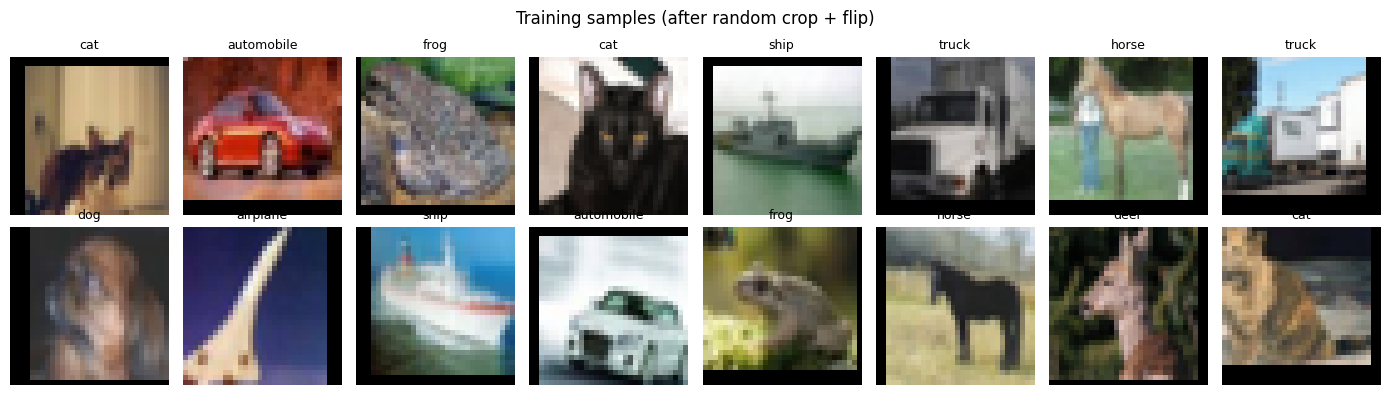

In [17]:
import torch
import matplotlib.pyplot as plt
from src.config import Config, CLASSES
from src.utils import set_seed
from src.data import get_dataloaders, denormalize

cfg = Config()
set_seed(cfg.seed)
train_loader, val_loader, test_loader = get_dataloaders(cfg)

# 1. Split sizes
print("Train images:", len(train_loader.dataset))
print("Val images:  ", len(val_loader.dataset))
print("Test images: ", len(test_loader.dataset))
print("Train batches per epoch:", len(train_loader))

# 2. Class balance in validation
val_subset = val_loader.dataset
val_labels = torch.tensor([val_subset.dataset.targets[i] for i in val_subset.indices])
print("Val images per class:", torch.bincount(val_labels).tolist())

# 3. Batch shape
images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape))

# 4. Normalization check
print(f"Pixel mean: {images.mean():.3f}   Pixel std: {images.std():.3f}")

# Show 16 training images
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lbl in zip(axes.flat, images[:16], labels[:16]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(CLASSES[lbl], fontsize=9)
    ax.axis("off")
plt.suptitle("Training samples (after random crop + flip)")
plt.tight_layout()
plt.savefig("outputs/sample_images.png", dpi=120)
plt.show()

## Step 4 — Baseline CNN Model

### `src/models.py` — the model, built from scratch
The model has two parts:

**1. Feature extractor (finds patterns in the image)**
It has 3 stages. Each stage has:
- **Conv layer** (two per stage): slides small 3x3 filters over the image to find patterns.
  Early stages find simple things (edges, colours). Later stages find bigger things (eyes, wheels).
- **BatchNorm**: keeps the numbers inside the network in a stable range, so training is faster and smoother.
- **ReLU**: keeps positive values and sets negative values to 0. This lets the model learn complex patterns.
- **MaxPool**: makes the image half the size, keeping the strongest signals.

Image size and channels through the stages:
- Input: 32x32, 3 channels (RGB)
- Stage 1: 16x16, 64 channels
- Stage 2: 8x8, 128 channels
- Stage 3: 4x4, 256 channels

**2. Classification head (makes the final decision)**
- **Average pooling**: turns each 4x4 map into 1 number, so we get 256 numbers.
- **Dropout (30%)**: during training, randomly turns off 30% of these numbers. The model cannot depend on a few features, so it generalizes better.
- **Linear layer**: turns 256 numbers into 10 scores, one per class. The highest score is the prediction.

Note: conv layers use `bias=False` because BatchNorm right after already adds its own shift, so a bias would do nothing.

This file also contains the residual model and the deeper models used in Step 7 and Step 7b.

In [13]:
%%writefile src/models.py
"""Models built from scratch (no pre-trained weights).
- BaselineCNN   : plain VGG-style CNN (Part 1)
- ResidualCNN   : same size, with residual blocks (Part 2, Option A)
- DeepCNN       : deeper version (2 blocks per stage), built with either
                  PlainBlock (no shortcut) or ResidualBlock (with shortcut) - Step 7b
"""
import torch.nn as nn


def conv_bn_relu(in_ch: int, out_ch: int) -> nn.Sequential:
    """3x3 conv -> BatchNorm -> ReLU. Padding=1 keeps the image size the same."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


# ---------- Baseline ----------
class BaselineCNN(nn.Module):
    """Small VGG-style CNN: 3 stages of (conv-bn-relu x2 + maxpool), then a classifier head."""

    def __init__(self, num_classes: int = 10, dropout: float = 0.3):
        super().__init__()
        self.features = nn.Sequential(
            # Stage 1: 32x32 -> 16x16
            conv_bn_relu(3, 64),
            conv_bn_relu(64, 64),
            nn.MaxPool2d(2),
            # Stage 2: 16x16 -> 8x8
            conv_bn_relu(64, 128),
            conv_bn_relu(128, 128),
            nn.MaxPool2d(2),
            # Stage 3: 8x8 -> 4x4
            conv_bn_relu(128, 256),
            conv_bn_relu(256, 256),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),   # (256, 4, 4) -> (256, 1, 1)
            nn.Flatten(),              # -> 256 numbers
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# ---------- Blocks ----------
class ResidualBlock(nn.Module):
    """Simplified ResNet basic block: out = ReLU( BN(conv(ReLU(BN(conv(x))))) + shortcut(x) )."""

    def __init__(self, in_ch: int, out_ch: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)

        # If size or channels change, resize x with a 1x1 conv so it can be added
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)   # the residual connection
        return self.relu(out)


class PlainBlock(nn.Module):
    """Same two conv layers as ResidualBlock, but WITHOUT the shortcut (control model)."""

    def __init__(self, in_ch: int, out_ch: int, stride: int = 1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.body(x)


# ---------- Residual (Part 2, Option A) ----------
class ResidualCNN(nn.Module):
    """Stem + 3 residual blocks (64 -> 128 -> 256 channels), same head as the baseline."""

    def __init__(self, num_classes: int = 10, dropout: float = 0.3):
        super().__init__()
        self.stem = conv_bn_relu(3, 64)                    # 32x32
        self.layers = nn.Sequential(
            ResidualBlock(64, 64, stride=1),               # 32x32
            ResidualBlock(64, 128, stride=2),              # 16x16
            ResidualBlock(128, 256, stride=2),             # 8x8
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),   # (256, 8, 8) -> (256, 1, 1)
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        return self.classifier(x)


# ---------- Deeper models (Step 7b depth experiment) ----------
class DeepCNN(nn.Module):
    """Stem + 3 stages x `blocks_per_stage` blocks. `block` is PlainBlock or ResidualBlock.
    With 2 blocks per stage: 1 + 3*2*2 = 13 conv layers."""

    def __init__(self, block, blocks_per_stage: int = 2, num_classes: int = 10, dropout: float = 0.3):
        super().__init__()
        self.stem = conv_bn_relu(3, 64)
        layers, in_ch = [], 64
        for out_ch, stride in [(64, 1), (128, 2), (256, 2)]:
            for i in range(blocks_per_stage):
                layers.append(block(in_ch, out_ch, stride if i == 0 else 1))
                in_ch = out_ch
        self.layers = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        return self.classifier(x)


# ---------- Helpers ----------
def get_model(name: str, cfg) -> nn.Module:
    """Build a model by name, using settings from the config."""
    if name == "baseline":
        return BaselineCNN(num_classes=cfg.num_classes, dropout=cfg.dropout)
    if name == "residual":
        return ResidualCNN(num_classes=cfg.num_classes, dropout=cfg.dropout)
    if name == "deep_plain":
        return DeepCNN(PlainBlock, blocks_per_stage=2, num_classes=cfg.num_classes, dropout=cfg.dropout)
    if name == "deep_residual":
        return DeepCNN(ResidualBlock, blocks_per_stage=2, num_classes=cfg.num_classes, dropout=cfg.dropout)
    raise ValueError(f"Unknown model name: {name}")


def count_params(model: nn.Module) -> int:
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Overwriting src/models.py


### Check the model
We check 3 things:
- **Shape**: 4 images in must give 4 x 10 scores out.
- **Size**: count the parameters (the numbers the model learns).
- **Starting loss**: before training, the model is just guessing, so each class gets about 1/10 chance.
  The expected loss is ln(10) = 2.303. If our loss is close to this, the model is set up correctly.

In [19]:
import math
import torch
import torch.nn as nn
from src.config import Config
from src.utils import set_seed
from src.data import get_dataloaders
from src.models import get_model, count_params

cfg = Config()
set_seed(cfg.seed)

model = get_model("baseline", cfg).to(cfg.device)
print(model)

# 1. Shape check with random input
dummy = torch.randn(4, 3, 32, 32, device=cfg.device)
print("\nOutput shape:", tuple(model(dummy).shape))

# 2. Parameter count
print(f"Trainable parameters: {count_params(model):,}")

# 3. Starting loss on one real batch (no training yet)
train_loader, _, _ = get_dataloaders(cfg)
images, labels = next(iter(train_loader))
images, labels = images.to(cfg.device), labels.to(cfg.device)

model.eval()
with torch.no_grad():
    loss = nn.CrossEntropyLoss()(model(images), labels)
print(f"Starting loss: {loss.item():.3f}   (expected about {math.log(10):.3f})")

BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (4): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, 

### `src/train.py` — the training script
**One training epoch = the model sees all 45,000 training images once, in 352 batches.**
For each batch:
1. The model makes predictions.
2. **Loss** (CrossEntropy) measures how wrong the predictions are.
3. **Backward pass** works out how to change each weight to reduce the loss.
4. **Optimizer** (SGD with momentum) updates the weights.
5. **LR scheduler** (OneCycle) updates the learning rate.

After each epoch we check the model on the 5,000 validation images (no training here, only measuring).

**Learning rate schedule (OneCycle):**
The learning rate (step size) starts small, rises to 0.1 in the first ~30% of training, then slowly drops to near 0.
Big steps early help the model learn fast. Small steps at the end help it settle on good weights.

**Other parts:**
- **Mixed precision (AMP)**: uses 16-bit numbers where safe, so the GPU trains faster.
- **Checkpoints**: `last_<model>.pt` is saved every epoch. `best_<model>.pt` is saved only when validation accuracy improves.
- **History**: loss, accuracy and learning rate for each epoch are saved to `history.csv`, then plotted to `curves.png`.
- **MLflow**: logs all settings and per-epoch results, so every run is recorded and can be compared.

Important: the test set is NOT loaded in this script. Only validation is used to choose the best model.

Note: train accuracy can be lower than validation accuracy early on. This is normal: during training, images are augmented and dropout is on, which makes the task harder.

In [25]:
%%writefile src/train.py
"""Training script.
Usage:  python -m src.train --model baseline            (full run, epochs from config)
        python -m src.train --model baseline --epochs 2 (quick test run)
"""
import argparse
import json
import os
import time
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn

from src.config import Config
from src.data import get_dataloaders
from src.models import get_model, count_params
from src.utils import set_seed, save_checkpoint, plot_curves

try:
    import mlflow
except ImportError:
    mlflow = None


# ---------- One epoch of training ----------
def train_one_epoch(model, loader, criterion, optimizer, scheduler, scaler, device, use_amp):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()   # backward pass (scaled for mixed precision)
        scaler.step(optimizer)          # update weights
        scaler.update()
        scheduler.step()                # OneCycle: update LR every batch

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total


# ---------- Measure on validation/test (no training) ----------
@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total


# ---------- MLflow helpers (training never fails because of logging) ----------
def mlflow_start(cfg, model_name, n_params):
    if mlflow is None:
        print("[MLflow] not installed, skipping tracking")
        return False
    try:
        mlflow_dir = os.path.abspath(cfg.mlflow_dir)
        os.makedirs(mlflow_dir, exist_ok=True)
        # Runs are stored in a SQLite database file; plots/CSVs go to mlruns/artifacts
        mlflow.set_tracking_uri("sqlite:///" + os.path.join(mlflow_dir, "mlflow.db"))
        if mlflow.get_experiment_by_name("cifar10") is None:
            artifact_dir = Path(mlflow_dir, "artifacts").as_uri()
            mlflow.create_experiment("cifar10", artifact_location=artifact_dir)
        mlflow.set_experiment("cifar10")
        mlflow.start_run(run_name=f"{model_name}_{cfg.epochs}ep")
        mlflow.log_params({**cfg.to_dict(), "model": model_name, "trainable_params": n_params})
        return True
    except Exception as e:
        print(f"[MLflow] disabled: {e}")
        return False


def mlflow_safe(fn, *args, **kwargs):
    try:
        fn(*args, **kwargs)
    except Exception as e:
        print(f"[MLflow] logging error (ignored): {e}")


# ---------- Main ----------
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, default="baseline")
    parser.add_argument("--epochs", type=int, default=None, help="override config epochs")
    args = parser.parse_args()

    cfg = Config()
    if args.epochs:
        cfg.epochs = args.epochs
    set_seed(cfg.seed)
    device = cfg.device
    use_amp = cfg.use_amp and device == "cuda"

    # Data: train + validation only. Test set is NOT used during training.
    train_loader, val_loader, _ = get_dataloaders(cfg)

    model = get_model(args.model, cfg).to(device)
    n_params = count_params(model)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(
        model.parameters(), lr=cfg.lr, momentum=cfg.momentum,
        nesterov=cfg.nesterov, weight_decay=cfg.weight_decay,
    )
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=cfg.lr, epochs=cfg.epochs, steps_per_epoch=len(train_loader),
    )
    scaler = torch.amp.GradScaler(device, enabled=use_amp)

    # Output paths
    out_dir = os.path.join(cfg.output_dir, args.model)
    os.makedirs(out_dir, exist_ok=True)
    os.makedirs(cfg.checkpoint_dir, exist_ok=True)
    best_path = os.path.join(cfg.checkpoint_dir, f"best_{args.model}.pt")
    last_path = os.path.join(cfg.checkpoint_dir, f"last_{args.model}.pt")

    use_mlflow = mlflow_start(cfg, args.model, n_params)

    print(f"Model: {args.model} | params: {n_params:,} | device: {device} | AMP: {use_amp} | epochs: {cfg.epochs}", flush=True)

    history = []
    best_val_acc, best_epoch = 0.0, 0
    start_time = time.time()

    for epoch in range(1, cfg.epochs + 1):
        t0 = time.time()
        lr_now = optimizer.param_groups[0]["lr"]

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scheduler, scaler, device, use_amp)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device, use_amp)
        epoch_time = time.time() - t0

        history.append({
            "epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
            "val_loss": val_loss, "val_acc": val_acc, "lr": lr_now, "epoch_time_sec": epoch_time,
        })

        # Checkpoints
        is_best = val_acc > best_val_acc
        if is_best:
            best_val_acc, best_epoch = val_acc, epoch
            save_checkpoint(best_path, model, optimizer, scheduler, scaler, epoch, best_val_acc, cfg)
        save_checkpoint(last_path, model, optimizer, scheduler, scaler, epoch, best_val_acc, cfg)

        # Save history every epoch (safe if Colab disconnects)
        pd.DataFrame(history).to_csv(os.path.join(out_dir, "history.csv"), index=False)

        if use_mlflow:
            mlflow_safe(mlflow.log_metrics, {
                "train_loss": train_loss, "train_acc": train_acc,
                "val_loss": val_loss, "val_acc": val_acc, "lr": lr_now,
            }, step=epoch)

        print(f"Epoch {epoch:02d}/{cfg.epochs} | lr {lr_now:.4f} | "
              f"train loss {train_loss:.4f} acc {train_acc*100:5.2f}% | "
              f"val loss {val_loss:.4f} acc {val_acc*100:5.2f}% | {epoch_time:5.1f}s"
              + ("  <- best" if is_best else ""), flush=True)

    total_time = time.time() - start_time

    # Curves + summary
    curves_path = os.path.join(out_dir, "curves.png")
    plot_curves(history, curves_path, title=f"{args.model} — training curves")
    summary = {
        "model": args.model, "trainable_params": n_params, "epochs": cfg.epochs,
        "best_val_acc": best_val_acc, "best_epoch": best_epoch,
        "total_train_time_sec": round(total_time, 1),
        "avg_epoch_time_sec": round(total_time / cfg.epochs, 1),
    }
    with open(os.path.join(out_dir, "train_summary.json"), "w") as f:
        json.dump(summary, f, indent=2)

    if use_mlflow:
        mlflow_safe(mlflow.log_metrics, {"best_val_acc": best_val_acc, "best_epoch": best_epoch})
        for fname in ["curves.png", "history.csv", "train_summary.json"]:
            mlflow_safe(mlflow.log_artifact, os.path.join(out_dir, fname))
        mlflow_safe(mlflow.end_run)

    print(f"\nDone in {total_time/60:.1f} min | best val acc {best_val_acc*100:.2f}% at epoch {best_epoch}")
    print(f"Best checkpoint: {best_path}")


if __name__ == "__main__":
    main()

Overwriting src/train.py


### Quick test run (2 epochs)
Before the full run, we train for only 2 epochs to check that everything works end to end:
training, validation, checkpoints, history, plots and MLflow.

In [26]:
!python -m src.train --model baseline --epochs 2

2026/10/21 10:03:54 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/21 10:03:54 INFO mlflow.store.db.utils: Updating database tables
Model: baseline | params: 1,148,874 | device: cuda | AMP: True | epochs: 2
Epoch 01/2 | lr 0.0040 | train loss 1.4127 acc 48.49% | val loss 1.2362 acc 57.60% |  18.9s  <- best
Epoch 02/2 | lr 0.0809 | train loss 0.8756 acc 68.89% | val loss 0.6767 acc 76.54% |  17.1s  <- best

Done in 0.6 min | best val acc 76.54% at epoch 2
Best checkpoint: checkpoints/best_baseline.pt


### Full training run (30 epochs)
We train the baseline model for 30 epochs, then show the loss and accuracy curves.

Model: baseline | params: 1,148,874 | device: cuda | AMP: True | epochs: 30
Epoch 01/30 | lr 0.0040 | train loss 1.4159 acc 48.11% | val loss 1.1572 acc 59.58% |  17.7s  <- best
Epoch 02/30 | lr 0.0069 | train loss 1.0140 acc 63.81% | val loss 1.1834 acc 60.34% |  16.8s  <- best
Epoch 03/30 | lr 0.0152 | train loss 0.8489 acc 70.23% | val loss 1.2548 acc 60.32% |  16.8s
Epoch 04/30 | lr 0.0280 | train loss 0.7401 acc 74.23% | val loss 0.8374 acc 71.10% |  16.6s  <- best
Epoch 05/30 | lr 0.0437 | train loss 0.6505 acc 77.67% | val loss 1.1680 acc 65.22% |  16.9s
Epoch 06/30 | lr 0.0604 | train loss 0.5938 acc 79.67% | val loss 0.8213 acc 73.28% |  16.8s  <- best
Epoch 07/30 | lr 0.0760 | train loss 0.5425 acc 81.30% | val loss 1.3067 acc 65.54% |  17.1s
Epoch 08/30 | lr 0.0888 | train loss 0.5023 acc 82.82% | val loss 0.6980 acc 77.70% |  16.9s  <- best
Epoch 09/30 | lr 0.0971 | train loss 0.4771 acc 83.72% | val loss 0.5809 acc 81.20% |  16.7s  <- best
Epoch 10/30 | lr 0.1000 | train l

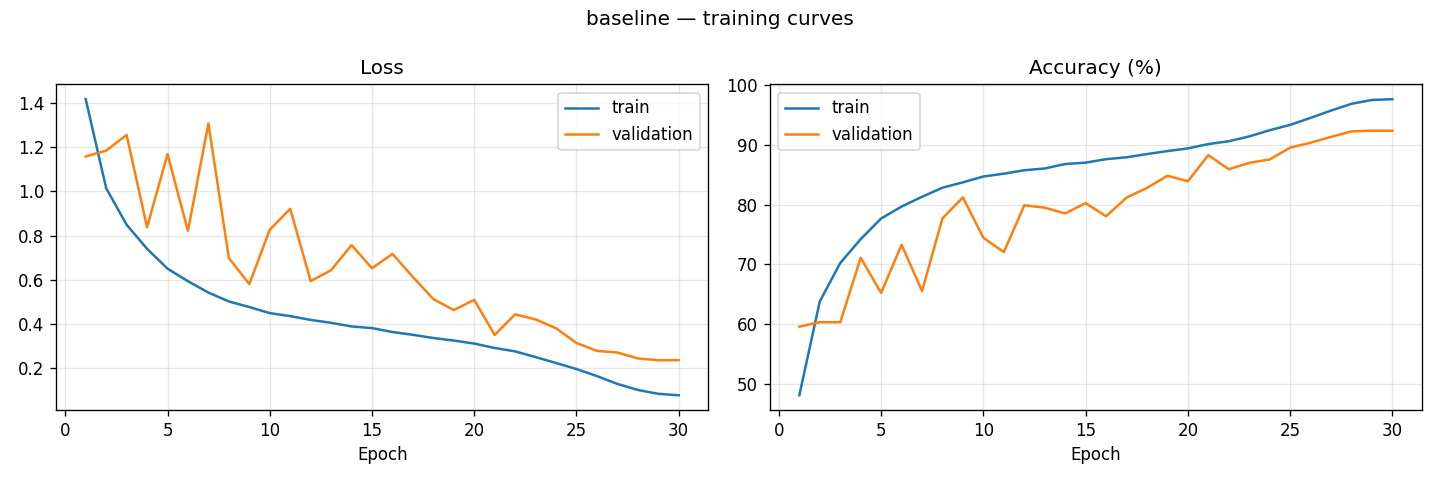

In [27]:
!python -m src.train --model baseline

from IPython.display import Image, display
display(Image("outputs/baseline/curves.png"))

## Step 6 — Evaluation on the Test Set

### `src/evaluate.py` — final test of the model
This is the first and only time we use the 10,000 test images.
The model has never seen them, and we did not use them to make any choices, so this score is an honest measure of how the model works on new images.

The script:
1. Loads the best saved model (`best_<model>.pt`, chosen by validation accuracy).
2. Predicts all 10,000 test images and measures **test accuracy**.
3. Measures **accuracy for each class**, to see which classes are easy and which are hard.
4. Draws a **confusion matrix**: a 10x10 table showing, for each true class, what the model predicted.
   Numbers on the diagonal are correct. Numbers off the diagonal are mistakes (for example, cats predicted as dogs).
5. Lists the **most common mistakes** (top 5 confused pairs).
6. Shows **16 misclassified images**: the ones where the model was most confident but still wrong.
   These show where the model is weakest.

Results are saved in `outputs/<model>/`: `metrics.json`, `confusion_matrix.png`, `misclassified.png`.

In [5]:
%%writefile src/evaluate.py
"""Evaluate a trained model on the TEST set (the only place the test set is used).
Usage: python -m src.evaluate --model baseline
"""
import argparse
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.config import Config, CLASSES
from src.data import get_dataloaders, denormalize
from src.models import get_model, count_params
from src.utils import set_seed, load_checkpoint


@torch.no_grad()
def predict(model, loader, device):
    """Return class probabilities, true labels and images for a whole dataset."""
    model.eval()
    all_probs, all_labels, all_images = [], [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_probs.append(torch.softmax(logits.float(), dim=1).cpu())
        all_labels.append(labels)
        all_images.append(images)
    return torch.cat(all_probs), torch.cat(all_labels), torch.cat(all_images)


def save_confusion_matrix(cm, out_path, title):
    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=120)
    plt.close(fig)


def save_misclassified(images, labels, preds, confs, out_path, title, n=16):
    """Show the n most confident wrong predictions."""
    wrong = (preds != labels).nonzero(as_tuple=True)[0]
    wrong = wrong[confs[wrong].argsort(descending=True)][:n]

    fig, axes = plt.subplots(2, 8, figsize=(16, 5))
    for ax, idx in zip(axes.flat, wrong.tolist()):
        ax.imshow(denormalize(images[idx]).permute(1, 2, 0))
        ax.set_title(f"true: {CLASSES[labels[idx]]}\npred: {CLASSES[preds[idx]]} ({confs[idx]*100:.0f}%)",
                     fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=120)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, default="baseline")
    args = parser.parse_args()

    cfg = Config()
    set_seed(cfg.seed)
    device = cfg.device
    out_dir = os.path.join(cfg.output_dir, args.model)
    os.makedirs(out_dir, exist_ok=True)

    # Load best checkpoint (chosen by validation accuracy during training)
    model = get_model(args.model, cfg).to(device)
    ckpt_path = os.path.join(cfg.checkpoint_dir, f"best_{args.model}.pt")
    ckpt = load_checkpoint(ckpt_path, model, device)
    print(f"Loaded {ckpt_path} (epoch {ckpt['epoch']}, val acc {ckpt['best_val_acc']*100:.2f}%)")

    # Test set: used here only
    _, _, test_loader = get_dataloaders(cfg)
    probs, labels, images = predict(model, test_loader, device)
    confs, preds = probs.max(dim=1)

    # Overall and per-class accuracy
    test_acc = (preds == labels).float().mean().item()
    cm = confusion_matrix(labels.numpy(), preds.numpy(), labels=list(range(len(CLASSES))))
    per_class = {c: float(cm[i, i] / cm[i].sum()) for i, c in enumerate(CLASSES)}

    # Top 5 confused pairs (true -> predicted)
    off_diag = cm.copy()
    np.fill_diagonal(off_diag, 0)
    top_pairs = []
    for flat_idx in off_diag.ravel().argsort()[::-1][:5]:
        t, p = divmod(int(flat_idx), len(CLASSES))
        top_pairs.append({"true": CLASSES[t], "pred": CLASSES[p], "count": int(off_diag[t, p])})

    # Print results
    print(f"\nTEST ACCURACY: {test_acc*100:.2f}%  ({int((preds == labels).sum())}/{len(labels)} correct)")
    print("\nPer-class accuracy:")
    for c, a in sorted(per_class.items(), key=lambda x: x[1]):
        print(f"  {c:12s} {a*100:6.2f}%")
    print("\nMost common mistakes (true -> predicted):")
    for p in top_pairs:
        print(f"  {p['true']:10s} -> {p['pred']:10s} {p['count']} images")

    # Save plots
    save_confusion_matrix(cm, os.path.join(out_dir, "confusion_matrix.png"),
                          f"{args.model} — confusion matrix (test acc {test_acc*100:.2f}%)")
    save_misclassified(images, labels, preds, confs, os.path.join(out_dir, "misclassified.png"),
                       f"{args.model} — most confident mistakes on the test set")

    # Save metrics (merge with training summary if it exists)
    metrics = {}
    summary_path = os.path.join(out_dir, "train_summary.json")
    if os.path.exists(summary_path):
        with open(summary_path) as f:
            metrics.update(json.load(f))
    metrics.update({
        "model": args.model,
        "trainable_params": count_params(model),
        "checkpoint_epoch": ckpt["epoch"],
        "best_val_acc": ckpt["best_val_acc"],
        "test_acc": test_acc,
        "per_class_test_acc": per_class,
        "top_confusions": top_pairs,
    })
    with open(os.path.join(out_dir, "metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2)
    print(f"\nSaved: {out_dir}/metrics.json, confusion_matrix.png, misclassified.png")


if __name__ == "__main__":
    main()

Writing src/evaluate.py


### Run evaluation on the baseline model

Loaded checkpoints/best_baseline.pt (epoch 29, val acc 92.36%)

TEST ACCURACY: 91.74%  (9174/10000 correct)

Per-class accuracy:
  cat           83.20%
  dog           87.70%
  bird          89.20%
  horse         92.00%
  airplane      92.10%
  truck         93.10%
  deer          93.60%
  frog          95.10%
  ship          95.10%
  automobile    96.30%

Most common mistakes (true -> predicted):
  cat        -> dog        76 images
  dog        -> cat        73 images
  truck      -> automobile 33 images
  bird       -> cat        28 images
  airplane   -> ship       27 images

Saved: outputs/baseline/metrics.json, confusion_matrix.png, misclassified.png


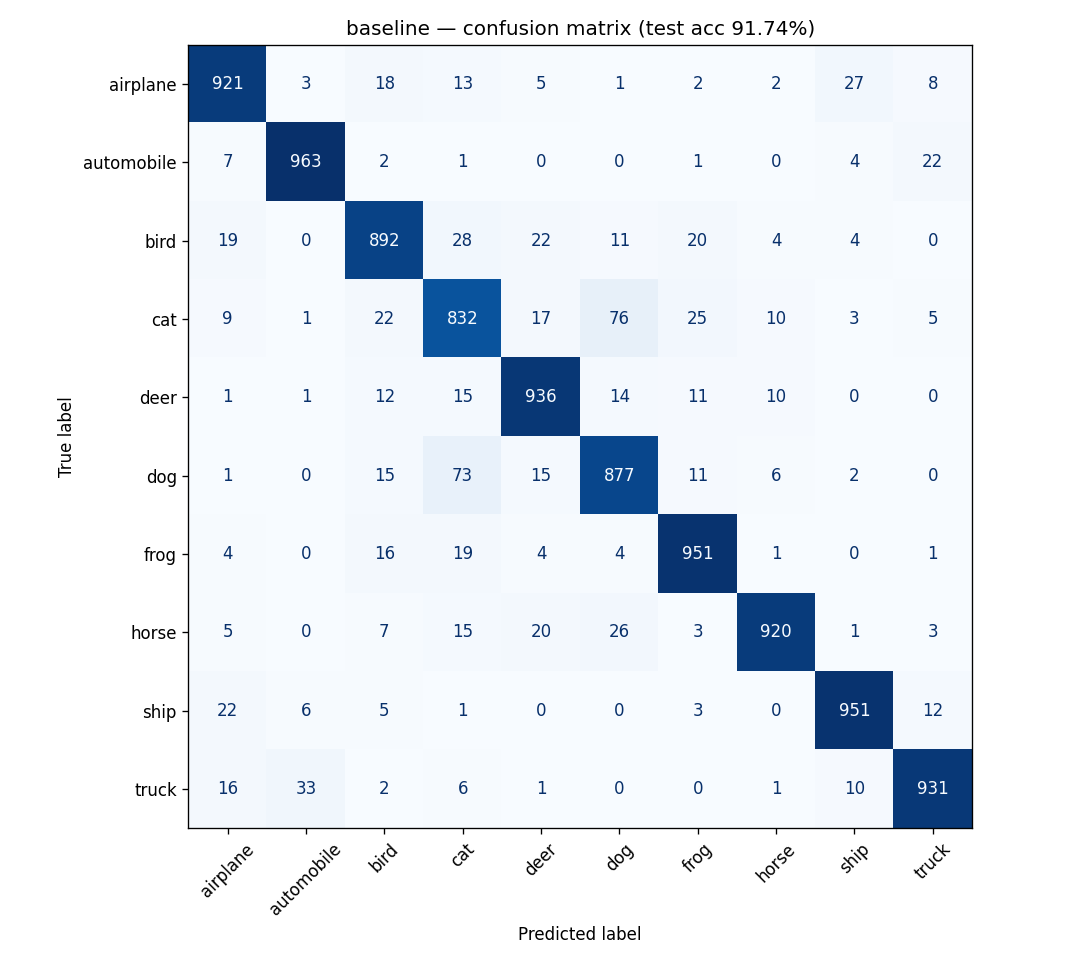

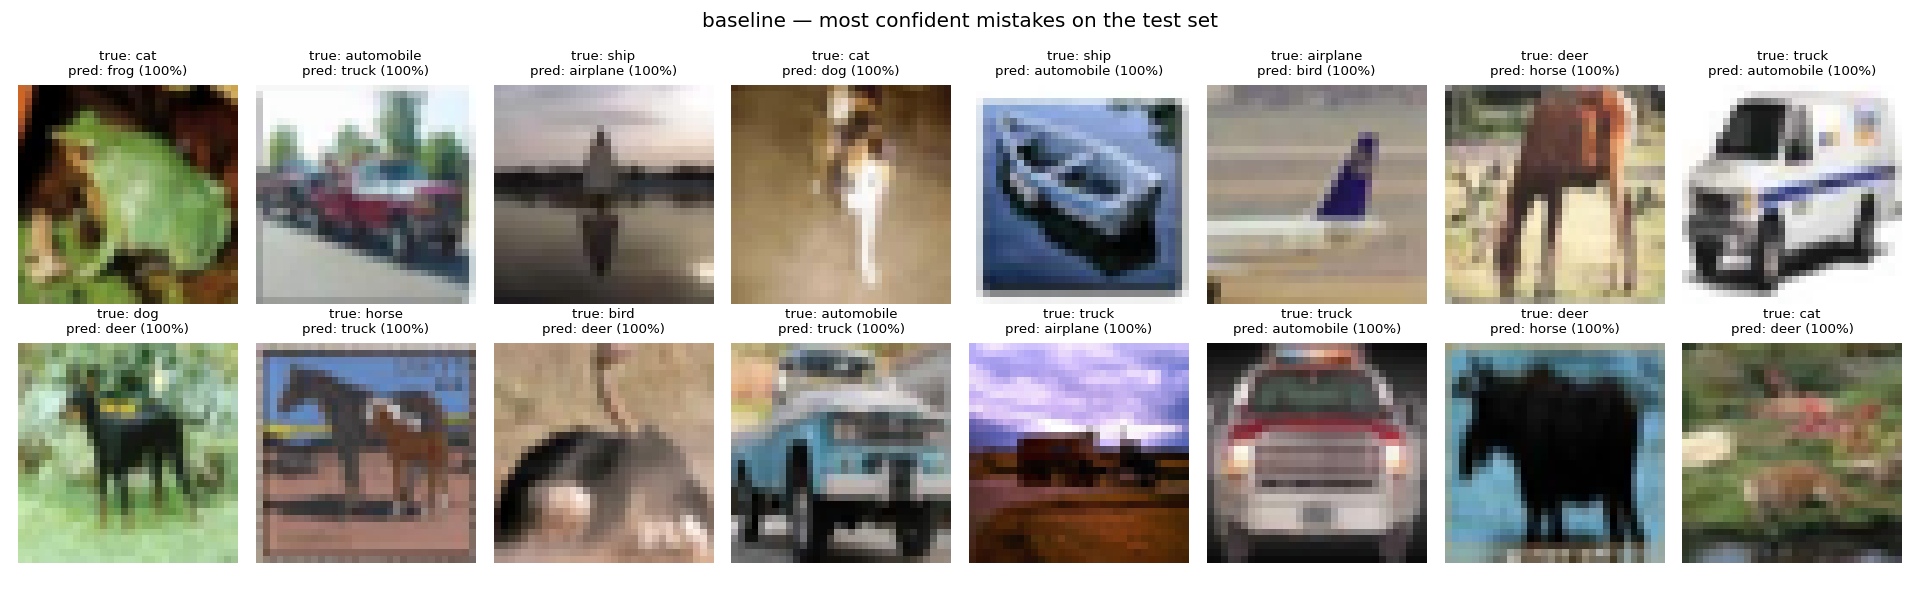

In [6]:
!python -m src.evaluate --model baseline

from IPython.display import Image, display
display(Image("outputs/baseline/confusion_matrix.png"))
display(Image("outputs/baseline/misclassified.png"))

## Step 7 — Model Improvement: Residual Block (Part 2, Option A)

### What is a residual block?
In a normal block, the input goes through layers and comes out changed:
    output = layers(x)

In a residual block, we also add the original input back at the end (a "shortcut"):
    output = layers(x) + x

Why this helps:
- The layers only need to learn the **change** to the input, not the whole thing again. This is easier.
- During training, the learning signal can flow straight back through the shortcut, so deeper networks train better.

When the block changes the image size or the number of channels, `x` no longer fits.
Then the shortcut uses a small 1x1 conv to resize `x` so it can be added.

### ResidualCNN — our improved model
- Stem: one conv layer (3 → 64 channels), 32x32
- Residual block 1: 64 → 64 channels, 32x32
- Residual block 2: 64 → 128 channels, 16x16 (stride 2 halves the size)
- Residual block 3: 128 → 256 channels, 8x8
- Same head as the baseline: average pool → dropout 30% → linear (10 classes)

To keep the comparison fair, it works at the same image sizes and channel widths as the baseline, with a similar number of parameters (~1.23M vs 1.15M).
It is trained with exactly the same settings (data, seed, optimizer, schedule, 30 epochs).

### Check the residual model
Same checks as the baseline: output shape, parameter count and starting loss (should be close to 2.303).
We also check that a residual block keeps the size with stride 1 and halves it with stride 2.

In [10]:
import importlib
import torch
import torch.nn as nn
import src.models
importlib.reload(src.models)   # load the NEW models.py, not the old copy in memory
from src.config import Config
from src.utils import set_seed
from src.models import get_model, count_params, ResidualBlock

cfg = Config()
set_seed(cfg.seed)

# Residual block shape checks
x = torch.randn(4, 64, 32, 32)
print("Block stride 1:", tuple(ResidualBlock(64, 64, 1)(x).shape), "(expected (4, 64, 32, 32))")
print("Block stride 2:", tuple(ResidualBlock(64, 128, 2)(x).shape), "(expected (4, 128, 16, 16))")

# Both models: output shape, params, starting loss
for name in ["baseline", "residual"]:
    m = get_model(name, cfg).eval()
    out = m(torch.randn(8, 3, 32, 32))
    loss = nn.CrossEntropyLoss()(out, torch.randint(0, 10, (8,)))
    print(f"{name:9s} output {tuple(out.shape)} | params {count_params(m):,} | start loss {loss.item():.2f}")

Block stride 1: (4, 64, 32, 32) (expected (4, 64, 32, 32))
Block stride 2: (4, 128, 16, 16) (expected (4, 128, 16, 16))
baseline  output (8, 10) | params 1,148,874 | start loss 2.32
residual  output (8, 10) | params 1,227,594 | start loss 2.30


### Train the residual model (30 epochs, same settings as the baseline)

Model: residual | params: 1,227,594 | device: cuda | AMP: True | epochs: 30
Epoch 01/30 | lr 0.0040 | train loss 1.5558 acc 41.83% | val loss 1.4698 acc 49.06% |  18.5s  <- best
Epoch 02/30 | lr 0.0069 | train loss 1.1717 acc 57.64% | val loss 1.2571 acc 56.96% |  17.7s  <- best
Epoch 03/30 | lr 0.0152 | train loss 1.0178 acc 63.86% | val loss 1.2860 acc 57.98% |  17.7s  <- best
Epoch 04/30 | lr 0.0280 | train loss 0.9082 acc 67.88% | val loss 1.1808 acc 61.02% |  17.6s  <- best
Epoch 05/30 | lr 0.0437 | train loss 0.8035 acc 71.86% | val loss 1.0832 acc 64.86% |  17.8s  <- best
Epoch 06/30 | lr 0.0604 | train loss 0.7273 acc 74.58% | val loss 1.0019 acc 66.56% |  17.7s  <- best
Epoch 07/30 | lr 0.0760 | train loss 0.6597 acc 77.00% | val loss 0.8375 acc 72.88% |  17.5s  <- best
Epoch 08/30 | lr 0.0888 | train loss 0.6029 acc 78.99% | val loss 0.7093 acc 75.64% |  17.6s  <- best
Epoch 09/30 | lr 0.0971 | train loss 0.5682 acc 80.50% | val loss 0.6314 acc 79.08% |  17.7s  <- best
Epoch 

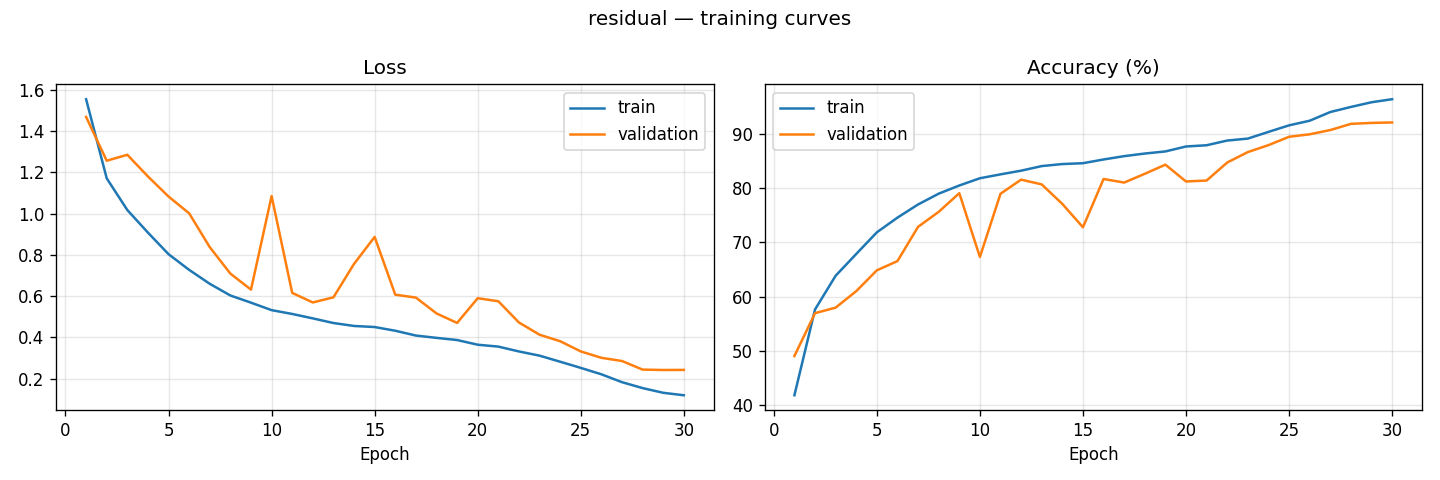

In [12]:
!python -m src.train --model residual

from IPython.display import Image, display
display(Image("outputs/residual/curves.png"))

### Evaluate the residual model on the test set

Loaded checkpoints/best_residual.pt (epoch 30, val acc 92.12%)

TEST ACCURACY: 91.06%  (9106/10000 correct)

Per-class accuracy:
  cat           81.60%
  dog           85.00%
  bird          87.20%
  deer          92.00%
  frog          92.40%
  horse         93.00%
  airplane      93.50%
  ship          94.90%
  truck         95.10%
  automobile    95.90%

Most common mistakes (true -> predicted):
  cat        -> dog        90 images
  dog        -> cat        82 images
  frog       -> bird       29 images
  automobile -> truck      28 images
  truck      -> automobile 27 images

Saved: outputs/residual/metrics.json, confusion_matrix.png, misclassified.png


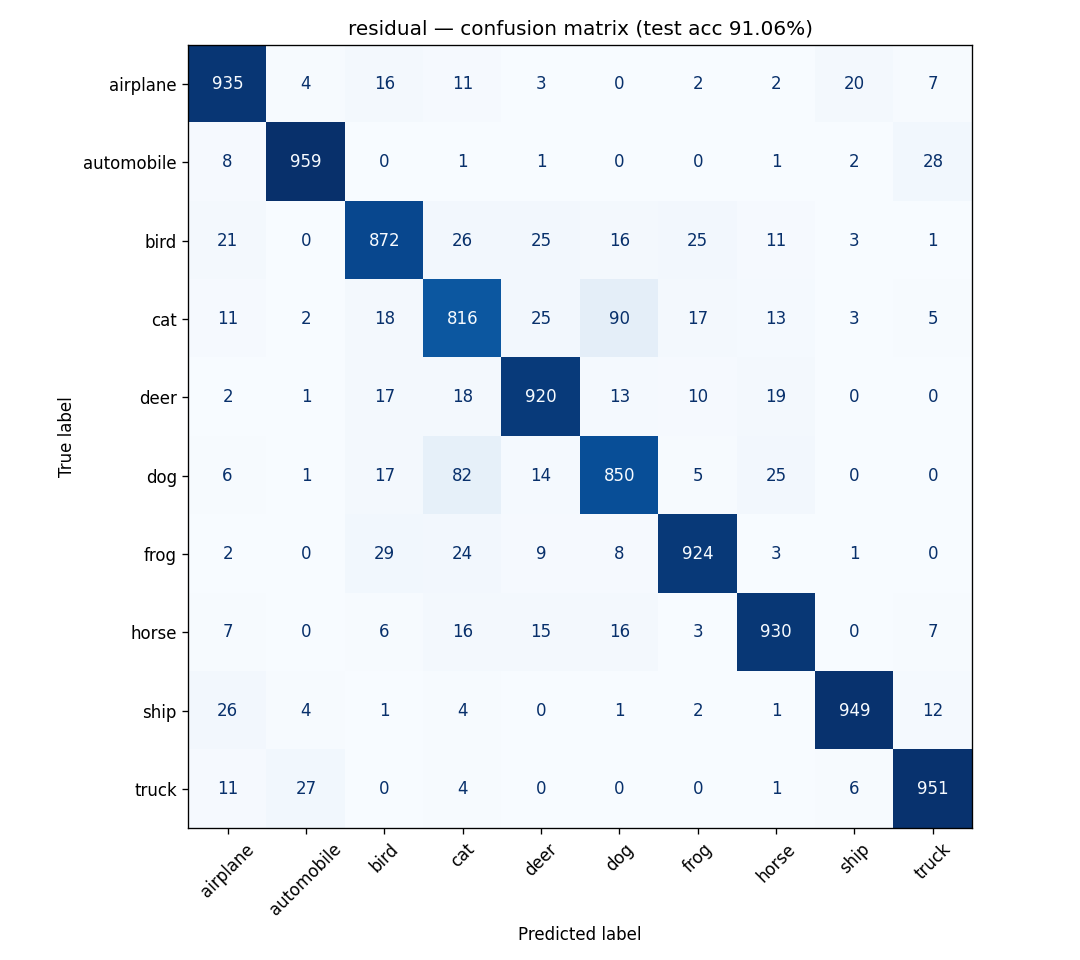

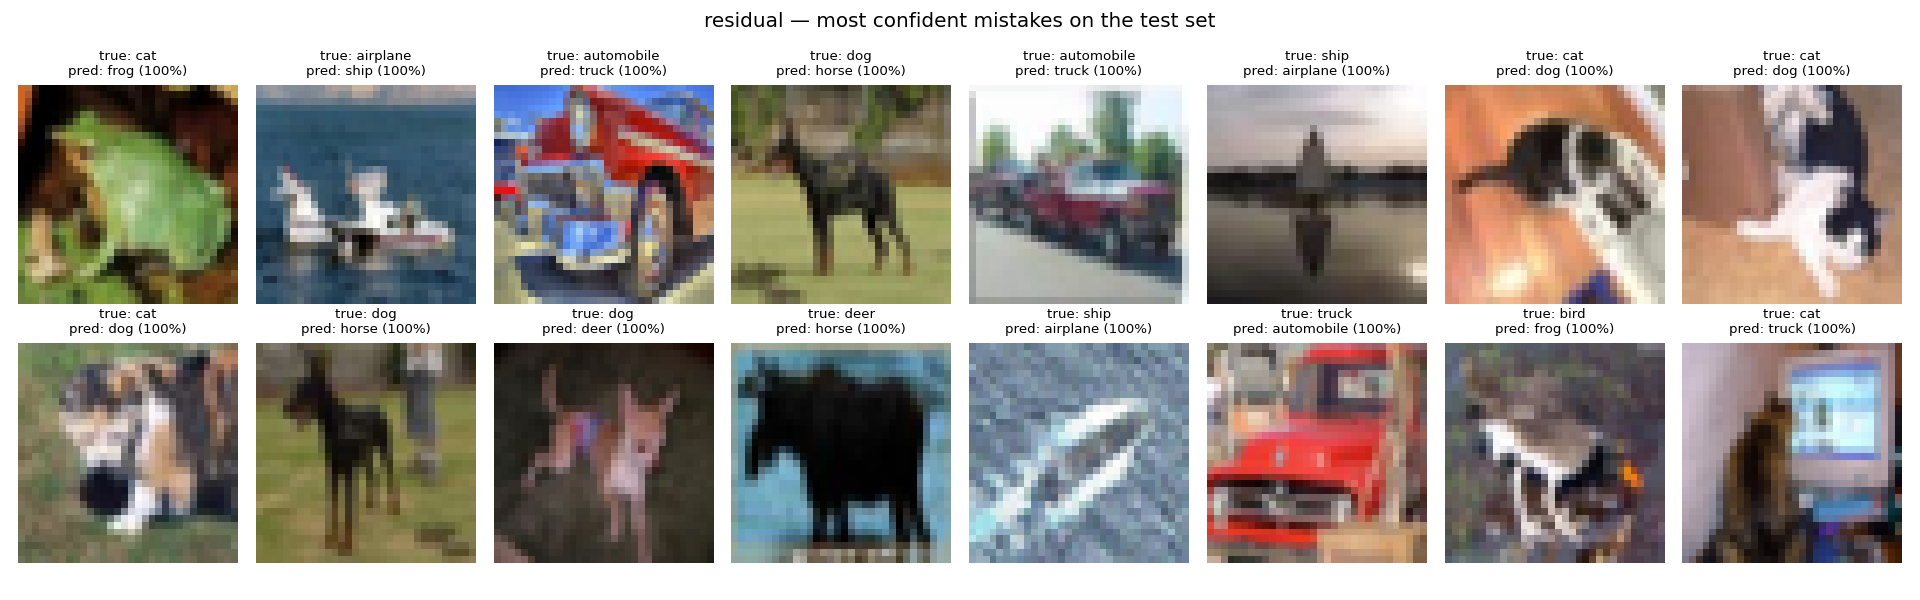

In [18]:
!python -m src.evaluate --model residual

display(Image("outputs/residual/confusion_matrix.png"))
display(Image("outputs/residual/misclassified.png"))

## Step 7b — Depth Experiment: Do Residual Connections Help Deeper Networks?

The same-size residual model (Step 7) did not improve on the baseline (validation 92.12% vs 92.36%, test 91.06% vs 91.74%). This is expected: our models have only 6–7 conv layers, and residual connections help most when networks are **deep**.

To test this fairly, we build two deeper models with **13 conv layers** (2 blocks per stage instead of 1):
- **deep_plain**: 13 conv layers, **no** shortcuts (~2.74M parameters)
- **deep_residual**: the same 13 conv layers, **with** shortcuts (~2.78M parameters)

Both have the same depth, almost the same size, and the same training settings.
The only difference is the shortcut, so any difference in accuracy comes from the residual connections.

In [14]:
import importlib
import torch
import torch.nn as nn
import src.models
importlib.reload(src.models)   # load the NEW models.py
from src.config import Config
from src.utils import set_seed
from src.models import get_model, count_params

cfg = Config()
set_seed(cfg.seed)

for name in ["baseline", "residual", "deep_plain", "deep_residual"]:
    m = get_model(name, cfg).eval()
    n_conv = sum(1 for mod in m.modules() if isinstance(mod, nn.Conv2d) and mod.kernel_size == (3, 3))
    out = m(torch.randn(8, 3, 32, 32))
    print(f"{name:14s} 3x3 conv layers: {n_conv:2d} | output {tuple(out.shape)} | params {count_params(m):,}")

baseline       3x3 conv layers:  6 | output (8, 10) | params 1,148,874
residual       3x3 conv layers:  7 | output (8, 10) | params 1,227,594
deep_plain     3x3 conv layers: 13 | output (8, 10) | params 2,735,946
deep_residual  3x3 conv layers: 13 | output (8, 10) | params 2,777,674


### Train the deep plain model (no shortcuts)

Model: deep_plain | params: 2,735,946 | device: cuda | AMP: True | epochs: 30
Epoch 01/30 | lr 0.0040 | train loss 1.5082 acc 43.62% | val loss 1.3525 acc 52.66% |  21.8s  <- best
Epoch 02/30 | lr 0.0069 | train loss 1.0097 acc 64.07% | val loss 1.8860 acc 49.88% |  20.4s
Epoch 03/30 | lr 0.0152 | train loss 0.8272 acc 71.16% | val loss 0.8296 acc 72.70% |  20.8s  <- best
Epoch 04/30 | lr 0.0280 | train loss 0.7107 acc 75.52% | val loss 0.7896 acc 73.60% |  21.3s  <- best
Epoch 05/30 | lr 0.0437 | train loss 0.6281 acc 78.54% | val loss 0.7057 acc 76.20% |  20.9s  <- best
Epoch 06/30 | lr 0.0604 | train loss 0.5701 acc 80.58% | val loss 0.8166 acc 73.34% |  21.9s
Epoch 07/30 | lr 0.0760 | train loss 0.5258 acc 82.06% | val loss 0.5831 acc 80.44% |  20.6s  <- best
Epoch 08/30 | lr 0.0888 | train loss 0.4872 acc 83.50% | val loss 0.7638 acc 75.48% |  22.2s
Epoch 09/30 | lr 0.0971 | train loss 0.4595 acc 84.43% | val loss 0.4722 acc 83.34% |  20.7s  <- best
Epoch 10/30 | lr 0.1000 | train

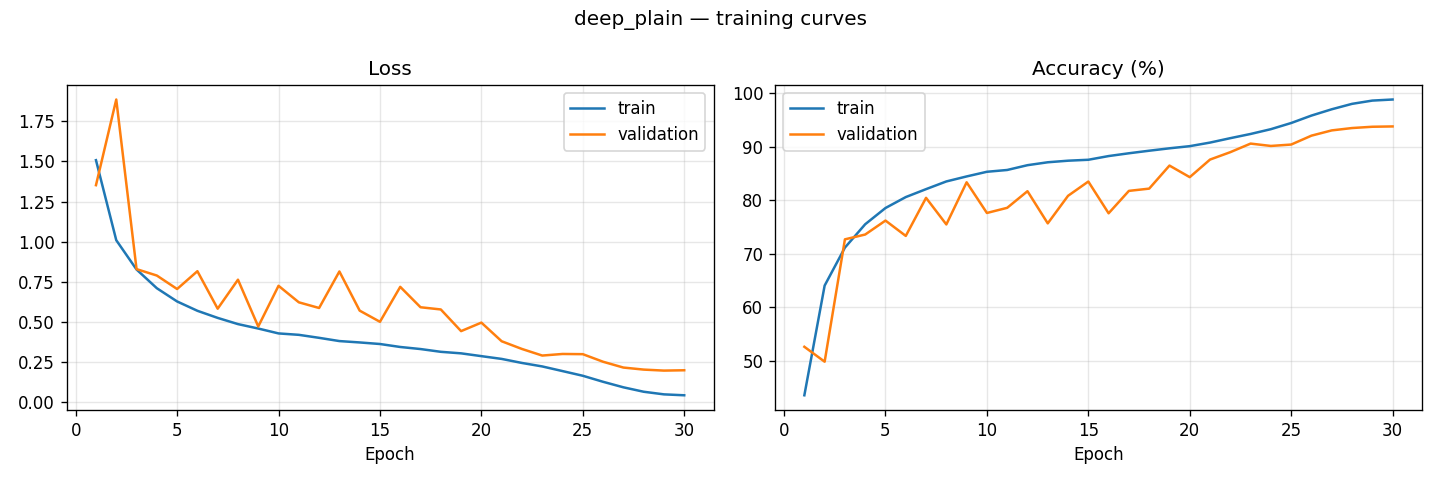

In [15]:
!python -m src.train --model deep_plain

from IPython.display import Image, display
display(Image("outputs/deep_plain/curves.png"))

### Train the deep residual model (with shortcuts)

In [ ]:
!python -m src.train --model deep_residual

display(Image("outputs/deep_residual/curves.png"))

Model: deep_residual | params: 2,777,674 | device: cuda | AMP: True | epochs: 30
Epoch 01/30 | lr 0.0040 | train loss 1.4517 acc 46.36% | val loss 1.2679 acc 56.38% |  20.7s  <- best
Epoch 02/30 | lr 0.0069 | train loss 1.0211 acc 63.53% | val loss 1.2421 acc 60.72% |  20.0s  <- best
Epoch 03/30 | lr 0.0152 | train loss 0.8383 acc 70.83% | val loss 0.9471 acc 70.34% |  20.8s  <- best
Epoch 04/30 | lr 0.0280 | train loss 0.7196 acc 75.29% | val loss 1.1599 acc 64.06% |  21.1s
Epoch 05/30 | lr 0.0437 | train loss 0.6213 acc 78.64% | val loss 0.6852 acc 77.08% |  20.8s  <- best
Epoch 06/30 | lr 0.0604 | train loss 0.5614 acc 80.93% | val loss 0.8222 acc 73.16% |  22.0s
Epoch 07/30 | lr 0.0760 | train loss 0.5043 acc 82.80% | val loss 0.6758 acc 78.28% |  20.4s  <- best
Epoch 08/30 | lr 0.0888 | train loss 0.4678 acc 84.06% | val loss 0.6356 acc 77.90% |  21.0s
Epoch 09/30 | lr 0.0971 | train loss 0.4371 acc 85.14% | val loss 0.4905 acc 83.84% |  20.6s  <- best
Epoch 10/30 | lr 0.1000 | tr

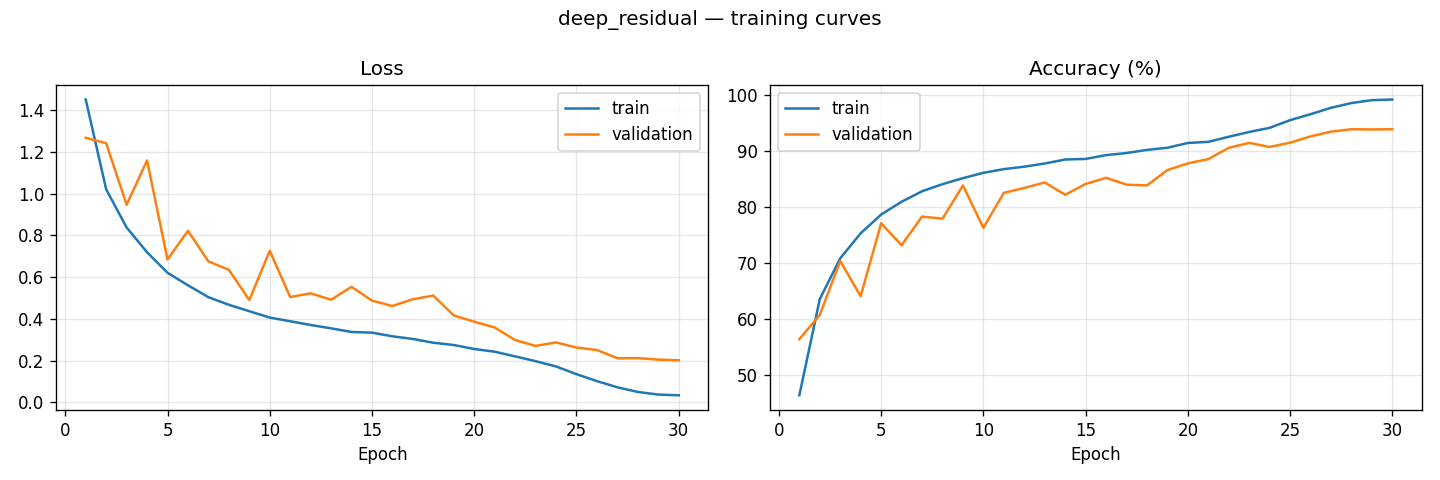

In [16]:
!python -m src.train --model deep_residual

display(Image("outputs/deep_residual/curves.png"))

### Evaluate both deep models on the test set

In [17]:
!python -m src.evaluate --model deep_plain
!python -m src.evaluate --model deep_residual

Loaded checkpoints/best_deep_plain.pt (epoch 30, val acc 93.76%)

TEST ACCURACY: 93.00%  (9300/10000 correct)

Per-class accuracy:
  cat           84.30%
  bird          88.90%
  dog           90.10%
  frog          94.00%
  deer          94.70%
  horse         94.80%
  airplane      95.00%
  truck         95.20%
  ship          96.30%
  automobile    96.70%

Most common mistakes (true -> predicted):
  cat        -> dog        79 images
  dog        -> cat        59 images
  bird       -> cat        32 images
  automobile -> truck      24 images
  truck      -> automobile 23 images

Saved: outputs/deep_plain/metrics.json, confusion_matrix.png, misclassified.png
Loaded checkpoints/best_deep_residual.pt (epoch 28, val acc 93.88%)

TEST ACCURACY: 93.21%  (9321/10000 correct)

Per-class accuracy:
  cat           86.60%
  dog           88.20%
  bird          89.60%
  deer          93.70%
  horse         94.90%
  truck         95.20%
  ship          95.40%
  airplane      95.50%
  frog      

## Step 8 — Comparing All Models

### `src/compare.py` — one table for all models
This script reads the saved results of each model (`metrics.json` and `history.csv`) and builds one comparison table.
It does not train or test anything again. It only collects numbers that were already saved.

Columns in the table:
- **Params**: model size.
- **Best val / Test acc**: accuracy on validation (used to pick the best epoch) and on the test set (final score).
- **Val→test**: how much accuracy drops from validation to test. A small drop means we did not overfit to validation.
- **Train–val gap**: train accuracy minus validation accuracy at the best epoch. A bigger gap means more overfitting.
- **High-LR val acc**: average and spread of validation accuracy while the learning rate is high (at least 50% of the peak).
  This shows how stable training is. Higher average and smaller spread = more stable.
- **Cat / Dog acc**: the two hardest classes.
- **Sec/epoch**: training speed.

It also draws one plot with all models together: validation accuracy and training loss per epoch.
Results are saved to `outputs/comparison.md` and `outputs/comparison_curves.png`.

In [19]:
%%writefile src/compare.py
"""Compare all trained models using their saved results (no retraining, no re-testing).
Usage: python -m src.compare
"""
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd

from src.config import Config

MODELS = ["baseline", "residual", "deep_plain", "deep_residual"]


def load_results(model, out_root):
    """Load metrics.json and history.csv for one model. Returns (None, None) if missing."""
    folder = os.path.join(out_root, model)
    metrics_path = os.path.join(folder, "metrics.json")
    history_path = os.path.join(folder, "history.csv")
    if not (os.path.exists(metrics_path) and os.path.exists(history_path)):
        return None, None
    with open(metrics_path) as f:
        metrics = json.load(f)
    return metrics, pd.read_csv(history_path)


def main():
    cfg = Config()
    rows, histories = [], {}

    for name in MODELS:
        m, h = load_results(name, cfg.output_dir)
        if m is None:
            print(f"Skipping {name}: results not found (train + evaluate it first)")
            continue
        histories[name] = h

        best_row = h.loc[h["val_acc"].idxmax()]
        high_lr = h[h["lr"] >= 0.5 * cfg.lr]          # epochs where LR >= 50% of peak
        per_class = m["per_class_test_acc"]

        rows.append({
            "Model": name,
            "Params": f"{m['trainable_params']:,}",
            "Best epoch": int(best_row["epoch"]),
            "Best val acc": f"{m['best_val_acc']*100:.2f}%",
            "Test acc": f"{m['test_acc']*100:.2f}%",
            "Val→test": f"{(m['test_acc'] - m['best_val_acc'])*100:+.2f}",
            "Train–val gap": f"{(best_row['train_acc'] - best_row['val_acc'])*100:.2f}",
            "High-LR val acc": f"{high_lr['val_acc'].mean()*100:.1f}% ± {high_lr['val_acc'].std()*100:.1f}",
            "Cat acc": f"{per_class['cat']*100:.1f}%",
            "Dog acc": f"{per_class['dog']*100:.1f}%",
            "Sec/epoch": f"{h['epoch_time_sec'].mean():.1f}",
        })

    if not rows:
        print("No results found.")
        return

    # ---- Markdown table ----
    headers = list(rows[0].keys())
    lines = ["| " + " | ".join(headers) + " |",
             "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        lines.append("| " + " | ".join(str(r[c]) for c in headers) + " |")
    high_lr_epochs = histories[rows[0]["Model"]].query(f"lr >= {0.5 * cfg.lr}")["epoch"]
    notes = [
        "",
        f"- All models: same data split, seed ({cfg.seed}), optimizer (SGD + OneCycle, peak LR {cfg.lr}), "
        f"batch size {cfg.batch_size}, {cfg.epochs} epochs.",
        "- Best epoch chosen by validation accuracy. The test set was used once per model, after training.",
        f"- High-LR phase = epochs {high_lr_epochs.min()}–{high_lr_epochs.max()} (LR ≥ 50% of peak). "
        "Value shown as mean ± standard deviation of validation accuracy.",
        "- Train–val gap is measured at the best epoch (train accuracy includes augmentation and dropout).",
    ]
    table_md = "# Model Comparison\n\n" + "\n".join(lines + notes) + "\n"
    out_md = os.path.join(cfg.output_dir, "comparison.md")
    with open(out_md, "w") as f:
        f.write(table_md)

    # ---- Overlay plot ----
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    for name, h in histories.items():
        ax1.plot(h["epoch"], h["val_acc"] * 100, label=name)
        ax2.plot(h["epoch"], h["train_loss"], label=name)
    ax1.set_title("Validation accuracy (%)")
    ax1.set_xlabel("Epoch")
    ax1.set_ylim(40, 100)
    ax2.set_title("Training loss")
    ax2.set_xlabel("Epoch")
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle("All models — same training settings")
    fig.tight_layout()
    out_png = os.path.join(cfg.output_dir, "comparison_curves.png")
    fig.savefig(out_png, dpi=120)
    plt.close(fig)

    print(table_md)
    print(f"Saved: {out_md}, {out_png}")


if __name__ == "__main__":
    main()

Writing src/compare.py


### Run the comparison

# Model Comparison

| Model | Params | Best epoch | Best val acc | Test acc | Val→test | Train–val gap | High-LR val acc | Cat acc | Dog acc | Sec/epoch |
|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 1,148,874 | 29 | 92.36% | 91.74% | -0.62 | 5.13 | 78.2% ± 5.1 | 83.2% | 87.7% | 17.0 |
| residual | 1,227,594 | 30 | 92.12% | 91.06% | -1.06 | 4.29 | 77.6% ± 5.5 | 81.6% | 85.0% | 18.2 |
| deep_plain | 2,735,946 | 30 | 93.76% | 93.00% | -0.76 | 5.02 | 80.2% ± 3.7 | 84.3% | 90.1% | 20.5 |
| deep_residual | 2,777,674 | 28 | 93.88% | 93.21% | -0.67 | 4.68 | 82.2% ± 4.0 | 86.6% | 88.2% | 20.6 |

- All models: same data split, seed (42), optimizer (SGD + OneCycle, peak LR 0.1), batch size 128, 30 epochs.
- Best epoch chosen by validation accuracy. The test set was used once per model, after training.
- High-LR phase = epochs 6–20 (LR ≥ 50% of peak). Value shown as mean ± standard deviation of validation accuracy.
- Train–val gap is measured at the best epoch (train accuracy includ

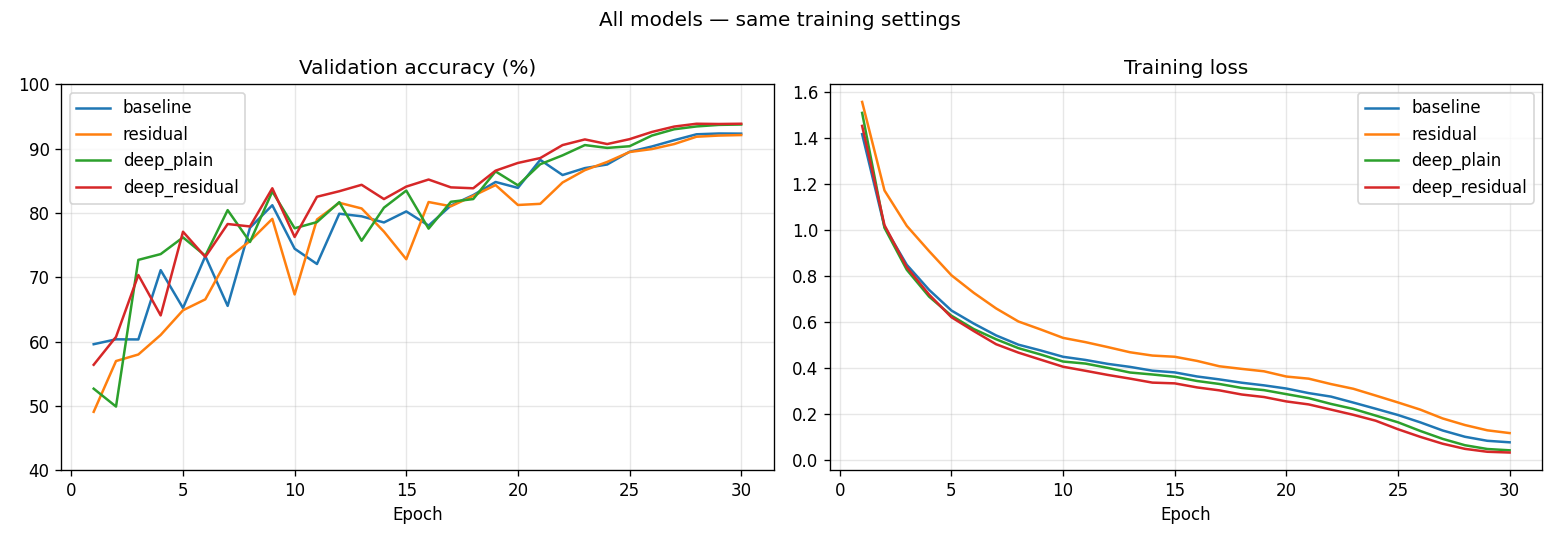

In [20]:
!python -m src.compare

from IPython.display import Image, display
display(Image("outputs/comparison_curves.png"))

### MLflow: all recorded training runs
Every training run was logged to MLflow automatically (settings, per-epoch metrics, plots).
Here we list the runs from the MLflow database to confirm all experiments are recorded.

In [21]:
import os
import mlflow

mlflow.set_tracking_uri("sqlite:///" + os.path.abspath("mlruns/mlflow.db"))
runs = mlflow.search_runs(experiment_names=["cifar10"])
cols = ["tags.mlflow.runName", "params.trainable_params", "params.epochs",
        "metrics.best_val_acc", "metrics.best_epoch", "status"]
print(runs[cols].sort_values("tags.mlflow.runName").to_string(index=False))

tags.mlflow.runName params.trainable_params params.epochs  metrics.best_val_acc  metrics.best_epoch   status
       baseline_2ep                 1148874             2                0.7654                 2.0 FINISHED
      baseline_30ep                 1148874            30                0.9236                29.0 FINISHED
    deep_plain_30ep                 2735946            30                0.9376                30.0 FINISHED
 deep_residual_30ep                 2777674            30                0.9388                28.0 FINISHED
      residual_30ep                 1227594            30                0.9212                30.0 FINISHED
      residual_30ep                 1227594            30                0.9212                30.0 FINISHED


## Step 9 — Optional Extensions

The brief lists some optional extensions. We do three of them:
1. **Mixed-precision training** — already done in Step 5 (AMP, `use_amp=True`).
2. **Unit tests** for model components (below).
3. **ONNX export and inference** (below).

### `tests/test_models.py` — unit tests
Small automatic checks that the code works as designed. They run on CPU in a few seconds and need no dataset download.
They check:
- Every model gives 10 scores per image.
- Every model has exactly the expected number of parameters (catches accidental changes).
- A residual block keeps the size with stride 1, and halves the size and changes channels with stride 2.
- An unknown model name gives a clear error.
- The same seed gives exactly the same starting weights (reproducibility).
- A few training steps on a small batch reduce the loss (the model can learn).
- The image transforms give the right shape, and normalization maps the average colour to about 0.

In [22]:
%%writefile tests/test_models.py
"""Unit tests for models, transforms and reproducibility.
Run from the project root:  python -m pytest tests -v
"""
import numpy as np
import pytest
import torch
import torch.nn as nn
from PIL import Image

from src.config import Config
from src.data import get_transforms
from src.models import get_model, count_params, ResidualBlock
from src.utils import set_seed

CFG = Config()
EXPECTED_PARAMS = {
    "baseline": 1_148_874,
    "residual": 1_227_594,
    "deep_plain": 2_735_946,
    "deep_residual": 2_777_674,
}


@pytest.mark.parametrize("name", list(EXPECTED_PARAMS))
def test_output_shape(name):
    model = get_model(name, CFG).eval()
    out = model(torch.randn(2, 3, 32, 32))
    assert out.shape == (2, 10)


@pytest.mark.parametrize("name, expected", list(EXPECTED_PARAMS.items()))
def test_param_count(name, expected):
    assert count_params(get_model(name, CFG)) == expected


def test_residual_block_stride1_keeps_shape():
    block = ResidualBlock(64, 64, stride=1)
    assert isinstance(block.shortcut, nn.Identity)          # plain identity shortcut
    assert block(torch.randn(2, 64, 32, 32)).shape == (2, 64, 32, 32)


def test_residual_block_stride2_downsamples():
    block = ResidualBlock(64, 128, stride=2)
    assert not isinstance(block.shortcut, nn.Identity)      # 1x1 conv shortcut
    assert block(torch.randn(2, 64, 32, 32)).shape == (2, 128, 16, 16)


def test_unknown_model_raises():
    with pytest.raises(ValueError):
        get_model("resnet50", CFG)


def test_same_seed_gives_identical_weights():
    set_seed(0)
    a = get_model("baseline", CFG)
    set_seed(0)
    b = get_model("baseline", CFG)
    for pa, pb in zip(a.parameters(), b.parameters()):
        assert torch.equal(pa, pb)


def test_training_steps_reduce_loss():
    set_seed(0)
    model = get_model("baseline", CFG).train()
    x, y = torch.randn(16, 3, 32, 32), torch.randint(0, 10, (16,))
    optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    loss_fn = nn.CrossEntropyLoss()

    first_loss = loss_fn(model(x), y).item()
    for _ in range(20):
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
    assert loss.item() < 0.5 * first_loss


def test_transforms_shape_and_normalization():
    train_tf, eval_tf = get_transforms()
    random_img = Image.fromarray(np.random.randint(0, 256, (32, 32, 3), dtype=np.uint8))
    assert train_tf(random_img).shape == (3, 32, 32)
    assert eval_tf(random_img).shape == (3, 32, 32)

    # An image filled with the dataset's average colour should normalize to about 0
    mean_img = Image.fromarray(np.full((32, 32, 3), [125, 123, 114], dtype=np.uint8))
    assert eval_tf(mean_img).abs().max() < 0.02

Writing tests/test_models.py


### Run the unit tests

In [23]:
!pip install -q pytest
!python -m pytest tests -v

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/task1_cifar10_classifier
plugins: typeguard-4.6.0, platformdirs-4.13.3, anyio-4.15.1, langsmith-0.14.11
collected 14 items                                                             

tests/test_models.py::test_output_shape[baseline] PASSED                 [  7%]
tests/test_models.py::test_output_shape[residual] PASSED                 [ 14%]
tests/test_models.py::test_output_shape[deep_plain] PASSED               [ 21%]
tests/test_models.py::test_output_shape[deep_residual] PASSED            [ 28%]
tests/test_models.py::test_param_count[baseline-1148874] PASSED          [ 35%]
tests/test_models.py::test_param_count[residual-1227594] PASSED          [ 42%]
tests/test_models.py::test_param_count[deep_plain-2735946] PASSED        [ 50%]
tests/test_models.py::test_param_coun

### `src/export_onnx.py` — export the model to ONNX
ONNX is a standard model format. An ONNX model can run without PyTorch (for example with ONNX Runtime), on servers, phones or in other languages.
This is the usual first step to deploy a model.

The script:
1. Loads the best saved model and exports it to `checkpoints/<model>.onnx`. The batch size is flexible (1 image or many).
2. Checks the ONNX file is valid.
3. Runs the same 1,000 test images through **PyTorch** and through **ONNX Runtime**, and compares:
   - the biggest difference between their output scores (should be tiny, like 0.0001),
   - how often they predict the same class (should be 100%),
   - accuracy of each on these images (should be the same).
4. Measures the speed of one image on CPU with ONNX Runtime.

We export **deep_residual**, because it has the best **validation** accuracy (93.88%).
We pick by validation, not test, to keep the test set fair.

(1,000 images instead of 10,000 keeps this check quick on Colab's CPU.)

In [24]:
%%writefile src/export_onnx.py
"""Export a trained model to ONNX and check it matches PyTorch.
Usage: python -m src.export_onnx --model deep_residual
"""
import argparse
import json
import os
import time

import numpy as np
import onnx
import onnxruntime as ort
import torch

from src.config import Config
from src.data import get_dataloaders
from src.models import get_model
from src.utils import set_seed, load_checkpoint


def export_to_onnx(model, path):
    """Export with a flexible batch size. Tries the classic exporter first, then the newer one."""
    dummy = torch.randn(2, 3, 32, 32)
    try:
        torch.onnx.export(
            model, (dummy,), path,
            input_names=["image"], output_names=["logits"],
            dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}},
            opset_version=17, dynamo=False,
        )
        return "torchscript exporter"
    except Exception as e:
        print(f"Classic exporter not available ({type(e).__name__}); using dynamo exporter")
        torch.onnx.export(
            model, (dummy,), path,
            input_names=["image"], output_names=["logits"],
            dynamic_shapes={"x": {0: torch.export.Dim("batch")}},
            dynamo=True,
        )
        return "dynamo exporter"


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", type=str, default="deep_residual")
    parser.add_argument("--n_images", type=int, default=1000)
    args = parser.parse_args()

    cfg = Config()
    cfg.device = "cpu"          # export and compare on CPU
    set_seed(cfg.seed)

    # 1. Load best checkpoint
    model = get_model(args.model, cfg)
    ckpt_path = os.path.join(cfg.checkpoint_dir, f"best_{args.model}.pt")
    load_checkpoint(ckpt_path, model, "cpu")
    model.eval()

    # 2. Export + validate the file
    onnx_path = os.path.join(cfg.checkpoint_dir, f"{args.model}.onnx")
    method = export_to_onnx(model, onnx_path)
    onnx.checker.check_model(onnx.load(onnx_path))
    size_mb = os.path.getsize(onnx_path) / 1e6
    print(f"Exported {onnx_path} ({size_mb:.1f} MB) using {method}; ONNX check passed")

    # 3. Compare PyTorch vs ONNX Runtime on test images
    session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    input_name = session.get_inputs()[0].name
    _, _, test_loader = get_dataloaders(cfg)

    max_diff, agree, correct_pt, correct_ox, n = 0.0, 0, 0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            pt_logits = model(images).numpy()
            ox_logits = session.run(None, {input_name: images.numpy()})[0]
            max_diff = max(max_diff, float(np.abs(pt_logits - ox_logits).max()))
            pt_pred, ox_pred = pt_logits.argmax(1), ox_logits.argmax(1)
            agree += int((pt_pred == ox_pred).sum())
            correct_pt += int((pt_pred == labels.numpy()).sum())
            correct_ox += int((ox_pred == labels.numpy()).sum())
            n += len(labels)
            if n >= args.n_images:
                break

    # 4. Speed: one image at a time on CPU
    one = np.random.randn(1, 3, 32, 32).astype(np.float32)
    for _ in range(10):
        session.run(None, {input_name: one})            # warm-up
    t0 = time.time()
    for _ in range(100):
        session.run(None, {input_name: one})
    ms_per_image = (time.time() - t0) / 100 * 1000

    result = {
        "model": args.model,
        "onnx_file": onnx_path,
        "onnx_size_mb": round(size_mb, 2),
        "export_method": method,
        "images_compared": n,
        "max_abs_logit_diff": max_diff,
        "prediction_agreement": agree / n,
        "pytorch_acc_on_subset": correct_pt / n,
        "onnx_acc_on_subset": correct_ox / n,
        "onnx_cpu_ms_per_image": round(ms_per_image, 2),
    }
    with open(os.path.join(cfg.output_dir, "onnx_check.json"), "w") as f:
        json.dump(result, f, indent=2)

    print(f"\nCompared {n} test images:")
    print(f"  Max difference in output scores: {max_diff:.2e}")
    print(f"  Same predicted class:            {agree / n * 100:.2f}%")
    print(f"  PyTorch accuracy on these:       {correct_pt / n * 100:.2f}%")
    print(f"  ONNX accuracy on these:          {correct_ox / n * 100:.2f}%")
    print(f"  ONNX Runtime CPU speed:          {ms_per_image:.2f} ms per image")
    print(f"\nSaved: {cfg.output_dir}/onnx_check.json")


if __name__ == "__main__":
    main()

Writing src/export_onnx.py


### Export and check

In [25]:
!pip install -q onnxscript
!python -m src.export_onnx --model deep_residual

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.2/192.2 kB 15.3 MB/s eta 0:00:00
/content/drive/MyDrive/task1_cifar10_classifier/src/export_onnx.py:24: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
Exported checkpoints/deep_residual.onnx (11.1 MB) using torchscript exporter; ONNX check passed

Compared 1024 test images:
  Max difference in output scores: 5.72e-06
  Same predicted class:            100.00%
  PyTorch accuracy on these:       93.55%
  ONNX accuracy on these:          93.55%
  ONNX Runtime CPU speed:          8.38 ms per image

Saved: outputs/on

## Step 10 — Finishing: Requirements, README, Final Check

### `requirements.txt` — exact library versions
Lists every library with the exact version used, so anyone can install the same environment and get the same results.
We create it from the versions installed in this Colab session, so the numbers are exact, not typed by hand.

Note: PyTorch was the CUDA 13.0 build on Colab (`2.11.0+cu130`). The file lists `torch==2.11.0`, so it also installs on machines without a GPU.

In [26]:
import sys
from importlib.metadata import version

packages = ["torch", "torchvision", "numpy", "pandas", "matplotlib", "scikit-learn",
            "Pillow", "mlflow", "onnx", "onnxruntime", "onnxscript", "pytest"]

lines = [f"{p}=={version(p).split('+')[0]}" for p in packages]
with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print(f"Python {sys.version.split()[0]}\n")
print(open("requirements.txt").read())

Python 3.13.15

torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1
Pillow==11.3.0
mlflow==3.17.2
onnx==1.23.2
onnxruntime==1.31.0
onnxscript==0.7.2
pytest==8.4.2



In [27]:
%%writefile .gitignore
# Dataset (downloaded automatically by the code)
data/

# Only keep best checkpoints + ONNX
checkpoints/last_*.pt

# Python / Jupyter / pytest caches
__pycache__/
*.pyc
.pytest_cache/
.ipynb_checkpoints/

Writing .gitignore


In [28]:
!du -sh data checkpoints outputs mlruns src tests 2>/dev/null
!ls -lh checkpoints

341M	data
132M	checkpoints
1.3M	outputs
1.7M	mlruns
101K	src
30K	tests
total 132M
-rw------- 1 root root 8.8M Oct 21 10:13 best_baseline.pt
-rw------- 1 root root  21M Oct 21 12:23 best_deep_plain.pt
-rw------- 1 root root  22M Oct 21 12:54 best_deep_residual.pt
-rw------- 1 root root 9.5M Oct 21 12:01 best_residual.pt
-rw------- 1 root root  11M Oct 21 13:25 deep_residual.onnx
-rw------- 1 root root 8.8M Oct 21 10:14 last_baseline.pt
-rw------- 1 root root  21M Oct 21 12:23 last_deep_plain.pt
-rw------- 1 root root  22M Oct 21 12:55 last_deep_residual.pt
-rw------- 1 root root 9.5M Oct 21 12:01 last_residual.pt


### `README.md` — project documentation
Explains the project structure, training setup, design decisions, how to run the code, and all results.
All numbers come from the runs in this notebook.

In [30]:
%%writefile README.md
# CIFAR-10 Image Classification (PyTorch, from scratch)

A small CNN built from scratch in PyTorch to classify CIFAR-10 images (10 classes, 32×32 pixels),
plus a residual-block improvement (Part 2, Option A) and a controlled depth experiment.

**Best model:** `deep_residual` — **93.21% test accuracy** (93.88% validation).
**Baseline (Part 1):** **91.74% test accuracy** (92.36% validation).

---

## Brief checklist

| Requirement | Where |
|---|---|
| Load CIFAR-10, normalize, augment, batch, `DataLoader` | `src/data.py` |
| Small CNN from scratch: conv, BatchNorm, Dropout, classification head | `src/models.py` → `BaselineCNN` |
| Training loop: loss, accuracy, LR scheduling, checkpoints | `src/train.py` |
| Loss & accuracy curves | `outputs/<model>/curves.png` |
| Test accuracy | `src/evaluate.py` → `outputs/<model>/metrics.json` |
| Misclassified images | `outputs/<model>/misclassified.png` |
| Random seeds | `src/utils.py` → `set_seed()`, `seed_worker()`, `get_generator()` |
| Requirements file | `requirements.txt` |
| Part 2, Option A: residual block | `src/models.py` → `ResidualBlock`, `ResidualCNN`, `DeepCNN` |
| Baseline vs improved comparison | `src/compare.py` → `outputs/comparison.md` |
| Optional: mixed precision | `src/train.py` (AMP on GPU) |
| Optional: unit tests | `tests/test_models.py` (14 tests) |
| Optional: ONNX export + inference | `src/export_onnx.py` |
| Extra: experiment tracking | MLflow (`mlruns/mlflow.db`) |

---

## Project structure

```
task1_cifar10_classifier/
├── README.md
├── requirements.txt
├── .gitignore
├── cifar10_runner.ipynb       # Colab notebook that runs every step, with outputs
├── src/
│   ├── config.py              # all settings in one place
│   ├── utils.py               # seeds, checkpoint save/load, plotting
│   ├── data.py                # dataset, train/val split, transforms, DataLoaders
│   ├── models.py              # BaselineCNN, ResidualBlock, ResidualCNN, PlainBlock, DeepCNN
│   ├── train.py               # training loop + checkpoints + MLflow logging
│   ├── evaluate.py            # test accuracy, confusion matrix, misclassified images
│   ├── compare.py             # comparison table + overlay plot for all models
│   └── export_onnx.py         # ONNX export + check against PyTorch
├── tests/
│   └── test_models.py         # unit tests (pytest)
├── checkpoints/
│   ├── best_<model>.pt        # best checkpoint per model (chosen by validation accuracy)
│   └── deep_residual.onnx     # ONNX version of the best model
├── outputs/
│   ├── <model>/               # history.csv, curves.png, metrics.json,
│   │                          # confusion_matrix.png, misclassified.png
│   ├── sample_images.png      # augmented training samples
│   ├── comparison.md          # all-model comparison table
│   ├── comparison_curves.png  # all-model curves
│   └── onnx_check.json        # ONNX vs PyTorch check
└── mlruns/                    # MLflow tracking database + artifacts
```

The dataset is not included. It downloads automatically to `data/` on the first run.

---

## How to run

Run all commands from the project root.

```bash
pip install -r requirements.txt

# 1. Unit tests (CPU, ~10 s, no dataset needed)
python -m pytest tests -v

# 2. Train (downloads CIFAR-10 on first run)
python -m src.train --model baseline          # Part 1
python -m src.train --model residual          # Part 2
python -m src.train --model deep_plain        # depth experiment (no shortcuts)
python -m src.train --model deep_residual     # depth experiment (with shortcuts)
python -m src.train --model baseline --epochs 2   # quick smoke test

# 3. Evaluate on the test set (uses checkpoints/best_<model>.pt)
python -m src.evaluate --model baseline

# 4. Compare all models
python -m src.compare

# 5. Export the best model to ONNX and check it matches PyTorch
python -m src.export_onnx --model deep_residual

# 6. (Optional) Browse experiments in the MLflow UI
mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db
```

- The `best_*.pt` checkpoints are included, so steps 3–5 work **without retraining**.
- Model names: `baseline`, `residual`, `deep_plain`, `deep_residual`.
- **On Colab:** open `cifar10_runner.ipynb`, set Runtime → T4 GPU, run the Setup cell, then run the cells in order.
- **Without a GPU** the code still runs (mixed precision switches off automatically), but one 30-epoch run takes hours instead of ~10 minutes.

---

## Training setup

| Setting | Value |
|---|---|
| Data split | 45,000 train / 5,000 validation (seeded split of the 50k training set) / 10,000 test |
| Augmentation (train only) | RandomCrop(32, padding=4), RandomHorizontalFlip |
| Normalization | CIFAR-10 per-channel mean (0.4914, 0.4822, 0.4465) and std (0.2470, 0.2435, 0.2616) |
| Batch size | 128 (352 batches per epoch) |
| Epochs | 30 |
| Loss | CrossEntropyLoss |
| Optimizer | SGD, momentum 0.9, Nesterov, weight decay 5e-4 |
| LR schedule | OneCycleLR, peak LR 0.1, updated every batch |
| Dropout | 0.3 (before the final linear layer) |
| Mixed precision | AMP (torch.autocast + GradScaler) on GPU |
| Seed | 42 (Python, NumPy, PyTorch, CUDA, DataLoader workers and shuffle) |
| Checkpoints | `last_<model>.pt` every epoch, `best_<model>.pt` when validation accuracy improves |
| Hardware | Google Colab, NVIDIA Tesla T4, Python 3.13.15, PyTorch 2.11.0 |

The **test set is used only in `evaluate.py`**, once per model, after training. All choices (best epoch, which model to export) use validation accuracy only.

---

## Model design decisions

**Baseline (`BaselineCNN`, 1,148,874 parameters)**
- 3 stages of `[Conv3x3 → BatchNorm → ReLU] × 2 → MaxPool`, with channels 64 → 128 → 256 and image size 32 → 16 → 8 → 4.
- Head: global average pooling → Dropout(0.3) → Linear(256, 10).
- **Why:** a small VGG-style network is a strong, simple baseline for 32×32 images. Two 3×3 convs per stage see the same area as one 5×5 conv with fewer parameters.
- **BatchNorm** after every conv keeps activations stable and allows a high learning rate (0.1).
- **`bias=False`** in convs, because the BatchNorm right after already adds a learned shift.
- **Global average pooling** instead of large fully connected layers: almost no parameters in the head and less overfitting.
- **Dropout only in the head**: augmentation and BatchNorm already regularize the conv layers.
- Built from scratch on purpose (the brief forbids pre-trained models). In a real project, a pre-trained model with fine-tuning would usually reach higher accuracy faster.

**Residual block (`ResidualBlock`)**
- `out = ReLU( BN(conv(ReLU(BN(conv(x))))) + shortcut(x) )`
- The shortcut is the identity when the shape stays the same, and a 1×1 conv + BatchNorm when the size or channels change (stride 2).

**Residual model (`ResidualCNN`, 1,227,594 parameters):** stem conv (64) → 3 residual blocks (64, 128 stride 2, 256 stride 2) → same head. Similar size to the baseline (+6.9% parameters).

**Depth experiment (`DeepCNN`):** stem + 3 stages × 2 blocks = 13 conv layers, built either with `PlainBlock` (**no** shortcut, 2,735,946 parameters) or `ResidualBlock` (**with** shortcut, 2,777,674 parameters). Same depth, same size, same settings: the only difference is the shortcut. This is the controlled test of the residual idea.

**Training choices**
- **Validation split**: 5,000 training images are held out to pick the best epoch, so the test score stays an honest estimate.
- **OneCycle + SGD (Nesterov)**: LR warms up to 0.1 in the first ~30% of training, then decays to near 0. This trains fast in a fixed budget, and the final low-LR phase gives most of the last accuracy gains.
- **AMP** speeds up training on the T4 GPU.
- **Deterministic cuDNN** (`deterministic=True, benchmark=False`): slightly slower, but runs are repeatable.
- **MLflow with a SQLite backend**: MLflow 3.x no longer accepts the old folder-based store. Logging is wrapped so a tracking error can never stop training.

---

## Results

All models: same data split, seed 42, optimizer, schedule, batch size and 30 epochs.

| Model | Conv layers | Params | Best epoch | Best val acc | **Test acc** | Train–val gap | High-LR val acc | Sec/epoch |
|---|---|---|---|---|---|---|---|---|
| baseline | 6 | 1,148,874 | 29 | 92.36% | **91.74%** | 5.13 | 78.2% ± 5.1 | 17.0 |
| residual | 7 | 1,227,594 | 30 | 92.12% | **91.06%** | 4.29 | 77.6% ± 5.5 | 18.2 |
| deep_plain | 13 | 2,735,946 | 30 | 93.76% | **93.00%** | 5.02 | 80.2% ± 3.7 | 20.5 |
| deep_residual | 13 | 2,777,674 | 28 | 93.88% | **93.21%** | 4.68 | 82.2% ± 4.0 | 20.6 |

- *Train–val gap*: train accuracy minus validation accuracy at the best epoch (train accuracy is measured with augmentation and dropout on).
- *High-LR val acc*: mean ± std of validation accuracy in epochs 6–20, where the LR is at least 50% of its peak.
- Full table: `outputs/comparison.md`.

![All model curves](outputs/comparison_curves.png)

### Baseline (Part 1)
- **Test accuracy 91.74%** (9,174 / 10,000), within 0.62 points of validation (92.36%), so there is no overfitting to the validation set.
- Validation accuracy was noisy in the high-LR phase and rose steadily as OneCycle lowered the LR. The best epoch was 29.

![Baseline curves](outputs/baseline/curves.png)

### Part 2: does the residual block help?
**Controlled comparison (13 layers, with vs without shortcuts):**
- Final accuracy was almost the same: deep_residual is **+0.12 points on validation** and **+0.21 points on test** (21 images out of 10,000). This is too small to call a real improvement from one run.
- Shortcuts made the network **learn faster**: validation accuracy was **about 2.0 points higher** on average during the high-LR phase (82.2% vs 80.2%), and training loss was lower from epoch 5 to the end (final 0.034 vs 0.044). The spread of validation accuracy was similar (± 4.0 vs ± 3.7), so training was not clearly *more stable*, just faster.

**Same-size comparison (baseline vs residual):**
- The residual model did **not** improve on the baseline (val 92.12% vs 92.36%, test 91.06% vs 91.74%), and its training loss was higher throughout.
- This comparison does not isolate the shortcut: the residual model also downsamples with stride-2 convs instead of MaxPool, has 7 instead of 6 conv layers, and pools from 8×8 instead of 4×4.

**Depth gave the largest gain:** going from 6 to 13 conv layers improved test accuracy by **+1.26 points** (plain) and **+1.47 points** (residual) over the baseline, for about 20% more time per epoch.

**Conclusion:** at 7–13 layers, residual connections speed up learning but do not change final accuracy much. Their main benefit, training much deeper networks (20–50+ layers) that plain networks struggle with, is beyond the scale of this task.

### Error analysis (baseline)
- Hardest classes: **cat (83.2%)**, dog (87.7%), bird (89.2%). Easiest: automobile (96.3%), ship and frog (95.1%).
- **Cat ↔ dog** is the biggest confusion: 76 + 73 = **149 of 826 errors (18%)**. Similar shape, fur and poses at 32×32 pixels.
- Other common mistakes: truck → automobile (33), bird → cat (28), airplane → ship (27; both often on a plain blue background).
- Animals are almost never confused with vehicles. Errors are mostly within these two groups.
- The most confident mistake for both the baseline and the residual model is a test image **labelled "cat" that appears to show a frog**. It is likely a label error in the dataset itself.

![Baseline misclassified](outputs/baseline/misclassified.png)
![Baseline confusion matrix](outputs/baseline/confusion_matrix.png)

### Optional extensions
- **Unit tests:** 14 tests pass in ~8 s (output shapes, exact parameter counts, residual block shapes and shortcut type, seed reproducibility, loss decreases with training, transforms and normalization).
- **ONNX:** `deep_residual.onnx` (11.1 MB) passes `onnx.checker`. On 1,024 test images, ONNX Runtime matches PyTorch: max logit difference **5.7e-06**, **100% same predictions**, identical accuracy. CPU speed **~8.4 ms per image**. Exported with the TorchScript-based exporter. The newer `torch.export` exporter is a fallback in the code.
- **Mixed precision:** AMP on GPU during training.
- **MLflow:** every run (settings, per-epoch metrics, curves, summaries) is logged to `mlruns/mlflow.db`.

---

## Reproducibility

- Seeds are fixed for Python, NumPy, PyTorch, CUDA, DataLoader workers and shuffle order, with deterministic cuDNN.
- Two separate 2-epoch runs of the baseline gave **identical** losses and accuracies at every epoch.
- The residual model was trained twice by accident. Both runs gave **identical** results (92.12% validation at epoch 30), as shown in MLflow.
- Exact library versions are in `requirements.txt`. Results can differ slightly on a different GPU or library version.

---

## Limitations and next steps

- **Single seed per model.** Differences under ~0.5 points (e.g. deep_residual vs deep_plain) are within normal seed-to-seed variation. Next step: 3–5 seeds per model and report mean ± std.
- **Overconfident mistakes.** The most confident errors have ≥99% confidence. Next step: temperature scaling (post-hoc, no retraining) or label smoothing.
- **Mild overfitting** (train–val gap of 4–5 points at the end). Stronger augmentation (Cutout, AutoAugment) or longer training could help.
- **Residual benefit at greater depth was not tested.** Next step: compare plain vs residual at 20+ layers.
- **Deployment:** the ONNX model is ready to serve. A FastAPI `/predict` endpoint loading it with ONNX Runtime would be the next step.

Overwriting README.md


In [31]:
from IPython.display import Markdown, display
display(Markdown(open("README.md").read()))

# CIFAR-10 Image Classification (PyTorch, from scratch)

A small CNN built from scratch in PyTorch to classify CIFAR-10 images (10 classes, 32×32 pixels),
plus a residual-block improvement (Part 2, Option A) and a controlled depth experiment.

**Best model:** `deep_residual` — **93.21% test accuracy** (93.88% validation).
**Baseline (Part 1):** **91.74% test accuracy** (92.36% validation).

---

## Brief checklist

| Requirement | Where |
|---|---|
| Load CIFAR-10, normalize, augment, batch, `DataLoader` | `src/data.py` |
| Small CNN from scratch: conv, BatchNorm, Dropout, classification head | `src/models.py` → `BaselineCNN` |
| Training loop: loss, accuracy, LR scheduling, checkpoints | `src/train.py` |
| Loss & accuracy curves | `outputs/<model>/curves.png` |
| Test accuracy | `src/evaluate.py` → `outputs/<model>/metrics.json` |
| Misclassified images | `outputs/<model>/misclassified.png` |
| Random seeds | `src/utils.py` → `set_seed()`, `seed_worker()`, `get_generator()` |
| Requirements file | `requirements.txt` |
| Part 2, Option A: residual block | `src/models.py` → `ResidualBlock`, `ResidualCNN`, `DeepCNN` |
| Baseline vs improved comparison | `src/compare.py` → `outputs/comparison.md` |
| Optional: mixed precision | `src/train.py` (AMP on GPU) |
| Optional: unit tests | `tests/test_models.py` (14 tests) |
| Optional: ONNX export + inference | `src/export_onnx.py` |
| Extra: experiment tracking | MLflow (`mlruns/mlflow.db`) |

---

## Project structure

```
task1_cifar10_classifier/
├── README.md
├── requirements.txt
├── .gitignore
├── cifar10_runner.ipynb       # Colab notebook that runs every step, with outputs
├── src/
│   ├── config.py              # all settings in one place
│   ├── utils.py               # seeds, checkpoint save/load, plotting
│   ├── data.py                # dataset, train/val split, transforms, DataLoaders
│   ├── models.py              # BaselineCNN, ResidualBlock, ResidualCNN, PlainBlock, DeepCNN
│   ├── train.py               # training loop + checkpoints + MLflow logging
│   ├── evaluate.py            # test accuracy, confusion matrix, misclassified images
│   ├── compare.py             # comparison table + overlay plot for all models
│   └── export_onnx.py         # ONNX export + check against PyTorch
├── tests/
│   └── test_models.py         # unit tests (pytest)
├── checkpoints/
│   ├── best_<model>.pt        # best checkpoint per model (chosen by validation accuracy)
│   └── deep_residual.onnx     # ONNX version of the best model
├── outputs/
│   ├── <model>/               # history.csv, curves.png, metrics.json,
│   │                          # confusion_matrix.png, misclassified.png
│   ├── sample_images.png      # augmented training samples
│   ├── comparison.md          # all-model comparison table
│   ├── comparison_curves.png  # all-model curves
│   └── onnx_check.json        # ONNX vs PyTorch check
└── mlruns/                    # MLflow tracking database + artifacts
```

The dataset is not included. It downloads automatically to `data/` on the first run.

---

## How to run

Run all commands from the project root.

```bash
pip install -r requirements.txt

# 1. Unit tests (CPU, ~10 s, no dataset needed)
python -m pytest tests -v

# 2. Train (downloads CIFAR-10 on first run)
python -m src.train --model baseline          # Part 1
python -m src.train --model residual          # Part 2
python -m src.train --model deep_plain        # depth experiment (no shortcuts)
python -m src.train --model deep_residual     # depth experiment (with shortcuts)
python -m src.train --model baseline --epochs 2   # quick smoke test

# 3. Evaluate on the test set (uses checkpoints/best_<model>.pt)
python -m src.evaluate --model baseline

# 4. Compare all models
python -m src.compare

# 5. Export the best model to ONNX and check it matches PyTorch
python -m src.export_onnx --model deep_residual

# 6. (Optional) Browse experiments in the MLflow UI
mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db
```

- The `best_*.pt` checkpoints are included, so steps 3–5 work **without retraining**.
- Model names: `baseline`, `residual`, `deep_plain`, `deep_residual`.
- **On Colab:** open `cifar10_runner.ipynb`, set Runtime → T4 GPU, run the Setup cell, then run the cells in order.
- **Without a GPU** the code still runs (mixed precision switches off automatically), but one 30-epoch run takes hours instead of ~10 minutes.

---

## Training setup

| Setting | Value |
|---|---|
| Data split | 45,000 train / 5,000 validation (seeded split of the 50k training set) / 10,000 test |
| Augmentation (train only) | RandomCrop(32, padding=4), RandomHorizontalFlip |
| Normalization | CIFAR-10 per-channel mean (0.4914, 0.4822, 0.4465) and std (0.2470, 0.2435, 0.2616) |
| Batch size | 128 (352 batches per epoch) |
| Epochs | 30 |
| Loss | CrossEntropyLoss |
| Optimizer | SGD, momentum 0.9, Nesterov, weight decay 5e-4 |
| LR schedule | OneCycleLR, peak LR 0.1, updated every batch |
| Dropout | 0.3 (before the final linear layer) |
| Mixed precision | AMP (torch.autocast + GradScaler) on GPU |
| Seed | 42 (Python, NumPy, PyTorch, CUDA, DataLoader workers and shuffle) |
| Checkpoints | `last_<model>.pt` every epoch, `best_<model>.pt` when validation accuracy improves |
| Hardware | Google Colab, NVIDIA Tesla T4, Python 3.13.15, PyTorch 2.11.0 |

The **test set is used only in `evaluate.py`**, once per model, after training. All choices (best epoch, which model to export) use validation accuracy only.

---

## Model design decisions

**Baseline (`BaselineCNN`, 1,148,874 parameters)**
- 3 stages of `[Conv3x3 → BatchNorm → ReLU] × 2 → MaxPool`, with channels 64 → 128 → 256 and image size 32 → 16 → 8 → 4.
- Head: global average pooling → Dropout(0.3) → Linear(256, 10).
- **Why:** a small VGG-style network is a strong, simple baseline for 32×32 images. Two 3×3 convs per stage see the same area as one 5×5 conv with fewer parameters.
- **BatchNorm** after every conv keeps activations stable and allows a high learning rate (0.1).
- **`bias=False`** in convs, because the BatchNorm right after already adds a learned shift.
- **Global average pooling** instead of large fully connected layers: almost no parameters in the head and less overfitting.
- **Dropout only in the head**: augmentation and BatchNorm already regularize the conv layers.
- Built from scratch on purpose (the brief forbids pre-trained models). In a real project, a pre-trained model with fine-tuning would usually reach higher accuracy faster.

**Residual block (`ResidualBlock`)**
- `out = ReLU( BN(conv(ReLU(BN(conv(x))))) + shortcut(x) )`
- The shortcut is the identity when the shape stays the same, and a 1×1 conv + BatchNorm when the size or channels change (stride 2).

**Residual model (`ResidualCNN`, 1,227,594 parameters):** stem conv (64) → 3 residual blocks (64, 128 stride 2, 256 stride 2) → same head. Similar size to the baseline (+6.9% parameters).

**Depth experiment (`DeepCNN`):** stem + 3 stages × 2 blocks = 13 conv layers, built either with `PlainBlock` (**no** shortcut, 2,735,946 parameters) or `ResidualBlock` (**with** shortcut, 2,777,674 parameters). Same depth, same size, same settings: the only difference is the shortcut. This is the controlled test of the residual idea.

**Training choices**
- **Validation split**: 5,000 training images are held out to pick the best epoch, so the test score stays an honest estimate.
- **OneCycle + SGD (Nesterov)**: LR warms up to 0.1 in the first ~30% of training, then decays to near 0. This trains fast in a fixed budget, and the final low-LR phase gives most of the last accuracy gains.
- **AMP** speeds up training on the T4 GPU.
- **Deterministic cuDNN** (`deterministic=True, benchmark=False`): slightly slower, but runs are repeatable.
- **MLflow with a SQLite backend**: MLflow 3.x no longer accepts the old folder-based store. Logging is wrapped so a tracking error can never stop training.

---

## Results

All models: same data split, seed 42, optimizer, schedule, batch size and 30 epochs.

| Model | Conv layers | Params | Best epoch | Best val acc | **Test acc** | Train–val gap | High-LR val acc | Sec/epoch |
|---|---|---|---|---|---|---|---|---|
| baseline | 6 | 1,148,874 | 29 | 92.36% | **91.74%** | 5.13 | 78.2% ± 5.1 | 17.0 |
| residual | 7 | 1,227,594 | 30 | 92.12% | **91.06%** | 4.29 | 77.6% ± 5.5 | 18.2 |
| deep_plain | 13 | 2,735,946 | 30 | 93.76% | **93.00%** | 5.02 | 80.2% ± 3.7 | 20.5 |
| deep_residual | 13 | 2,777,674 | 28 | 93.88% | **93.21%** | 4.68 | 82.2% ± 4.0 | 20.6 |

- *Train–val gap*: train accuracy minus validation accuracy at the best epoch (train accuracy is measured with augmentation and dropout on).
- *High-LR val acc*: mean ± std of validation accuracy in epochs 6–20, where the LR is at least 50% of its peak.
- Full table: `outputs/comparison.md`.

![All model curves](outputs/comparison_curves.png)

### Baseline (Part 1)
- **Test accuracy 91.74%** (9,174 / 10,000), within 0.62 points of validation (92.36%), so there is no overfitting to the validation set.
- Validation accuracy was noisy in the high-LR phase and rose steadily as OneCycle lowered the LR. The best epoch was 29.

![Baseline curves](outputs/baseline/curves.png)

### Part 2: does the residual block help?
**Controlled comparison (13 layers, with vs without shortcuts):**
- Final accuracy was almost the same: deep_residual is **+0.12 points on validation** and **+0.21 points on test** (21 images out of 10,000). This is too small to call a real improvement from one run.
- Shortcuts made the network **learn faster**: validation accuracy was **about 2.0 points higher** on average during the high-LR phase (82.2% vs 80.2%), and training loss was lower from epoch 5 to the end (final 0.034 vs 0.044). The spread of validation accuracy was similar (± 4.0 vs ± 3.7), so training was not clearly *more stable*, just faster.

**Same-size comparison (baseline vs residual):**
- The residual model did **not** improve on the baseline (val 92.12% vs 92.36%, test 91.06% vs 91.74%), and its training loss was higher throughout.
- This comparison does not isolate the shortcut: the residual model also downsamples with stride-2 convs instead of MaxPool, has 7 instead of 6 conv layers, and pools from 8×8 instead of 4×4.

**Depth gave the largest gain:** going from 6 to 13 conv layers improved test accuracy by **+1.26 points** (plain) and **+1.47 points** (residual) over the baseline, for about 20% more time per epoch.

**Conclusion:** at 7–13 layers, residual connections speed up learning but do not change final accuracy much. Their main benefit, training much deeper networks (20–50+ layers) that plain networks struggle with, is beyond the scale of this task.

### Error analysis (baseline)
- Hardest classes: **cat (83.2%)**, dog (87.7%), bird (89.2%). Easiest: automobile (96.3%), ship and frog (95.1%).
- **Cat ↔ dog** is the biggest confusion: 76 + 73 = **149 of 826 errors (18%)**. Similar shape, fur and poses at 32×32 pixels.
- Other common mistakes: truck → automobile (33), bird → cat (28), airplane → ship (27; both often on a plain blue background).
- Animals are almost never confused with vehicles. Errors are mostly within these two groups.
- The most confident mistake for both the baseline and the residual model is a test image **labelled "cat" that appears to show a frog**. It is likely a label error in the dataset itself.

![Baseline misclassified](outputs/baseline/misclassified.png)
![Baseline confusion matrix](outputs/baseline/confusion_matrix.png)

### Optional extensions
- **Unit tests:** 14 tests pass in ~8 s (output shapes, exact parameter counts, residual block shapes and shortcut type, seed reproducibility, loss decreases with training, transforms and normalization).
- **ONNX:** `deep_residual.onnx` (11.1 MB) passes `onnx.checker`. On 1,024 test images, ONNX Runtime matches PyTorch: max logit difference **5.7e-06**, **100% same predictions**, identical accuracy. CPU speed **~8.4 ms per image**. Exported with the TorchScript-based exporter. The newer `torch.export` exporter is a fallback in the code.
- **Mixed precision:** AMP on GPU during training.
- **MLflow:** every run (settings, per-epoch metrics, curves, summaries) is logged to `mlruns/mlflow.db`.

---

## Reproducibility

- Seeds are fixed for Python, NumPy, PyTorch, CUDA, DataLoader workers and shuffle order, with deterministic cuDNN.
- Two separate 2-epoch runs of the baseline gave **identical** losses and accuracies at every epoch.
- The residual model was trained twice by accident. Both runs gave **identical** results (92.12% validation at epoch 30), as shown in MLflow.
- Exact library versions are in `requirements.txt`. Results can differ slightly on a different GPU or library version.

---

## Limitations and next steps

- **Single seed per model.** Differences under ~0.5 points (e.g. deep_residual vs deep_plain) are within normal seed-to-seed variation. Next step: 3–5 seeds per model and report mean ± std.
- **Overconfident mistakes.** The most confident errors have ≥99% confidence. Next step: temperature scaling (post-hoc, no retraining) or label smoothing.
- **Mild overfitting** (train–val gap of 4–5 points at the end). Stronger augmentation (Cutout, AutoAugment) or longer training could help.
- **Residual benefit at greater depth was not tested.** Next step: compare plain vs residual at 20+ layers.
- **Deployment:** the ONNX model is ready to serve. A FastAPI `/predict` endpoint loading it with ONNX Runtime would be the next step.
